---

# DSC LOGIKA UI 2026: Credit Risk Prediction

*Predicting 90+ DPD within 12 months of origination for Indonesian consumer loans, scored by the KS statistic.*

---

## TeamName (DSCxxxx)

- Name 1 (Role)
- Name 2
- Name 3

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Exploratory Data Analysis**](#3)
4. [**Feature Engineering**](#4)
5. [**Validation Strategy**](#5)
6. [**Gradient Boosting Models**](#6)
7. [**Foundation and Neural Models**](#7)
8. [**Ensemble and KS Stability**](#8)
9. [**Submission**](#9)


---

# Introduction <a name="1"></a>

---

## Overview

*Credit risk is a central challenge in consumer lending. A lender has to judge, at the moment of the loan decision, whether an application is likely to run into serious repayment difficulty using only the information available at that time.*

*This competition frames the problem on a multi-table Indonesian consumer lending dataset. Each selected loan has a 12-month term, and the goal is to rank applications by their risk of reaching 90 or more days past due within 12 months of origination.*

## Aim

*Build a leak-free scoring pipeline that aggregates six behavioural tables into one row per application and produces a risk score with maximal and stable KS separation on both the public and the private leaderboard.*

## Metric

***The Kolmogorov-Smirnov (KS) statistic** measures the largest vertical gap between the cumulative score distributions of bad loans and good loans. It depends only on the ranking of scores, so calibration does not matter and rank-averaging is a safe way to blend models.*

$$KS = \max_s \left| F_1(s) - F_0(s) \right|$$

## Dataset

*Data sourced from the Kaggle competition DSC LOGIKA UI 2026.*

*The training set contains 70,000 selected applications (13.58% bad) and the test set contains 30,000. Every customer has exactly one selected application, and train and test customers are disjoint. About 30% of customers in both splits are thin-file, with no previous applications, repayment history or account data.*

*The dataset is used to engineer customer-level features that respect the `decision_datetime` information cutoff.*

**Attributes**

1.  `train/test_applications`  : Selected loan (amount, 12-month term, rate tier, installment, purpose)
2.  `customer_profiles`        : Age, region, employment, tenure, declared income, dependents, housing
3.  `previous_applications`    : Historical applications with decision, approved amount and rate
4.  `repayment_history`        : Installment-level amounts, payment dates and days past due
5.  `account_behavior`         : Monthly balances, inflows, outflows and low-balance days
6.  `bureau_observations`      : Up to three bureau reports per application (score, utilization, inquiries)
7.  `ecommerce_transactions`   : Item-level orders with category, payment method and status

**Target**
 `target`       : 1 if the loan reaches 90+ DPD within 12 months, 0 otherwise

## Approach: Behavioural Features + GBDT and Tabular Foundation Model Ensemble

*The approach aggregates every auxiliary table to the customer level with explicit cutoff filters. Window lengths are chosen from the exploratory analysis: repayment lateness is a stable trait, so full-history ratios are used, while e-commerce activity and cash-flow stress ramp up in the 3-4 months before the application, so recent-versus-baseline acceleration features are used.*

*Version 2 adds 38 features found by a residual analysis of the version 1 out-of-fold predictions. They cover lateness severity (how many months a late installment stays unpaid), first-installment and latest-loan behaviour, non-income inflows, bureau score trend, cancellations and night-time orders. The same analysis showed that risk is close to additive in log-odds across the signal families, so every tree library is run twice: a deep variant (as in version 1) and a shallow variant.*

*Version 3 keeps the version 2 features and tree models unchanged (public leaderboard 0.542) and changes only the non-tree members. A residual analysis of the version 2 predictions showed that both foundation models trailed the trees by about 0.025 KS in every segment and added nothing to the blend. The likely cause was our own setup rather than the models: the context was capped at 30,000 rows and 64 features, while TabPFN-3.5 supports up to one million rows. TabPFN-3.5 now sees the full training fold and 100 features, with a KV cache so that the context is encoded once per fold. Causilo (rank correlation 0.994 with TabPFN, blend weight 0) is dropped. LimiX-2 was tried in its place: without flash-attention it falls back to PyTorch SDPA, but on a T4 its first fold did not finish in three hours because every out-of-memory retry restarted the whole query, so it is left out. TabM, an efficient ensemble of MLPs with piecewise-linear embeddings, is added as a different inductive bias for a dataset whose risk signals are additive.*

*Three gradient boosting libraries (LightGBM, XGBoost on GPU, CatBoost on GPU) are trained with repeated stratified 5-fold CV. Out-of-fold predictions are rank-blended by greedy ensemble selection only when that beats an equal-weight tree blend on held-out halves, and the blend is checked for KS stability before submission.*

```
7 raw tables
    |
    +-- cutoff-filtered aggregations (one row per application, ~215 features)
         |
    +----------+-----------+-----------+-------------+-----------+
    |          |           |           |             |           |
  LightGBM   XGBoost    CatBoost    TabPFN-3.5    TabM
 deep+shallow deep+shallow deep+shallow  |            |
    |          |           |           |             |
    +----------+-- rank blend (greedy selection on OOF KS) ------+
                     |
              default_probability
```

*Train and test are a random split of the same period (PSI below 0.002 for every feature), so stratified K-fold is the correct validation scheme. The public-versus-private KS gap expected from sampling noise alone is about 0.01, so decisions are made on CV rather than on the public leaderboard.*

---

# Initialization <a name="2"></a>

---

## Environment Setup

The notebook targets a Kaggle GPU T4 x2 session with internet enabled (needed once to download the TabPFN-3.5 weights and the TabM package). TabPFN weights are gated: accept the licence on Hugging Face and store a token as a Kaggle secret named `TABPFN_TOKEN` (or `HF_TOKEN`). If a foundation model cannot be loaded, its step is skipped and the notebook still completes with the gradient boosting ensemble. On Kaggle the tree models take about 40 minutes and full-context TabPFN-3.5 about 25 minutes. TabM has a per-fold time cap and a total budget, so the whole run stays at roughly 2 hours.

In [1]:
!nvidia-smi

Tue Oct 13 12:17:24 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   56C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

The following cell installs all libraries used in this notebook.

In [2]:
%pip install -q polars==2.0.0 lightgbm xgboost catboost tabpfn tabm rtdl_num_embeddings

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.6/876.6 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 MB 38.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 850.0/850.0 kB 43.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 595.9/595.9 kB 25.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-polars-cu12 26.2.1 requires polars<1.36,>=1.30, but you have polars 2.0.0 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


## Import Libraries

In [3]:
import copy
import gc
import os
import random
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import torch
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier, Pool
from scipy.special import ndtri
from scipy.stats import ks_2samp, rankdata
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

try:
    from tabpfn import TabPFNClassifier
except Exception as e:
    TabPFNClassifier = None
    print('TabPFN unavailable:', repr(e))
try:
    import tabm
    import rtdl_num_embeddings
except Exception as e:
    tabm = None
    print('TabM unavailable:', repr(e))
try:
    from kaggle_secrets import UserSecretsClient
except Exception:
    UserSecretsClient = None

warnings.filterwarnings('ignore')
print('torch', torch.__version__, '| GPUs:', torch.cuda.device_count(), '| polars', pl.__version__)

torch 2.11.0+cu128 | GPUs: 2 | polars 2.0.0


## Seed Everything

In [4]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)

## Settings

All paths, hyperparameters, and environment flags are centralised here. The data directory is located automatically under `/kaggle/input`, so the notebook works regardless of the competition slug.

In [5]:
class Settings:
    SEED       = 42
    GBDT_SEEDS = [42, 7, 2026]
    N_FOLDS    = 5
    _ON_KAGGLE = Path('/kaggle/input').exists()

    DATA_DIR   = (
        next(Path('/kaggle/input').rglob('train_applications.csv')).parent
        if _ON_KAGGLE else Path('../data')
    )
    OUTPUT_DIR = Path('/kaggle/working') if _ON_KAGGLE else Path('../output')
    FIG_DIR    = OUTPUT_DIR / 'figures'

    USE_LGB     = True
    USE_XGB     = True
    USE_CAT     = True
    USE_TABPFN  = True
    USE_TABM    = True

    N_GPU          = torch.cuda.device_count()
    FM_N_FEATURES  = 100
    FM_MAX_CONTEXT = 60000
    FM_N_EST       = 4
    FM_CHUNK       = 10000
    TABPFN_BUDGET_MIN = 180
    TABM_EPOCHS   = 40
    TABM_PATIENCE = 6
    TABM_BATCH    = 512
    TABM_BINS     = 48
    TABM_LR       = 2e-3
    TABM_WD       = 3e-4
    TABM_FOLD_MAX_MIN = 4
    TABM_BUDGET_MIN   = 50
    ENS_ITERS      = 30

    LGB_PARAMS = dict(
        objective='binary', metric='auc', learning_rate=0.02, num_leaves=31,
        min_child_samples=100, feature_fraction=0.5, bagging_fraction=0.8, bagging_freq=1,
        lambda_l2=5.0, verbose=-1, n_jobs=4,
    )
    LGB_SHALLOW = dict(LGB_PARAMS, num_leaves=7, max_depth=3, min_child_samples=200,
                       feature_fraction=0.4, lambda_l2=10.0)
    XGB_PARAMS = dict(
        objective='binary:logistic', eval_metric='auc', learning_rate=0.02, max_depth=5,
        min_child_weight=5, subsample=0.8, colsample_bytree=0.5, reg_lambda=5.0,
        tree_method='hist', device='cuda' if torch.cuda.is_available() else 'cpu',
    )
    XGB_SHALLOW = dict(XGB_PARAMS, max_depth=3, min_child_weight=20, colsample_bytree=0.4, reg_lambda=10.0)
    CAT_PARAMS = dict(
        iterations=10000, learning_rate=0.03, depth=6, l2_leaf_reg=5, loss_function='Logloss',
        task_type='GPU' if torch.cuda.is_available() else 'CPU', od_type='Iter', od_wait=200,
        use_best_model=True, verbose=0,
    )
    CAT_SHALLOW = dict(CAT_PARAMS, depth=4, l2_leaf_reg=10)
    N_ROUNDS   = 10000
    EARLY_STOP = 200

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CFG.FIG_DIR.mkdir(parents=True, exist_ok=True)
print('data:', CFG.DATA_DIR)

data: /kaggle/input/competitions/data-science-competition-logika-ui-2026


The TabPFN-3.5 weights are gated, so the access token is read from Kaggle secrets when it exists. Missing secrets are not an error.

In [6]:
if UserSecretsClient is not None:
    for name in ['TABPFN_TOKEN', 'HF_TOKEN']:
        try:
            os.environ[name] = UserSecretsClient().get_secret(name)
            print('loaded secret', name)
        except Exception:
            pass
if 'TABPFN_TOKEN' not in os.environ and 'HF_TOKEN' in os.environ:
    os.environ['TABPFN_TOKEN'] = os.environ['HF_TOKEN']

loaded secret TABPFN_TOKEN
loaded secret HF_TOKEN


## Load Dataset

All seven tables are read with Polars and dates are parsed on load. No visualisation here.

In [7]:
TABLES = ['train_applications', 'test_applications', 'customer_profiles', 'previous_applications',
          'repayment_history', 'account_behavior', 'bureau_observations', 'ecommerce_transactions']
T = {t: pl.read_csv(CFG.DATA_DIR / f'{t}.csv', try_parse_dates=True, infer_schema_length=100000) for t in TABLES}
sample_sub = pl.read_csv(CFG.DATA_DIR / 'sample_submission.csv')
for t, df in T.items():
    print(f'{t:<24} {df.shape}')

train_applications       (70000, 10)
test_applications        (30000, 9)
customer_profiles        (100000, 8)
previous_applications    (201984, 11)
repayment_history        (1361341, 9)
account_behavior         (1084418, 10)
bureau_observations      (797563, 14)
ecommerce_transactions   (4359817, 10)


---

# Exploratory Data Analysis <a name="3"></a>

---

The analysis below reproduces the key findings of the offline EDA that shaped the feature set. All statistics use the competition KS definition, so the helpers are defined first and reused throughout the notebook.

## KS Utilities

`ks_score` matches the official scorer (`ks_2samp` on bad versus good scores). `ks_nan` treats missing values as their own bin at either extreme, which mirrors how tree models route missing values. `psi` measures train-to-test drift on train deciles.

In [8]:
def ks_score(y, s):
    y, s = np.asarray(y), np.asarray(s, dtype=float)
    return float(ks_2samp(s[y == 1], s[y == 0]).statistic)

def ks_nan(y, s):
    s = np.asarray(s, dtype=float)
    if np.isnan(s).all():
        return 0.0
    lo, hi = np.nanmin(s) - 1, np.nanmax(s) + 1
    return max(ks_score(y, np.where(np.isnan(s), lo, s)), ks_score(y, np.where(np.isnan(s), hi, s)))

def psi(a, b, bins=10):
    a, b = np.asarray(a, float), np.asarray(b, float)
    qs = np.unique(np.nanquantile(a, np.linspace(0, 1, bins + 1))) if (~np.isnan(a)).any() else np.array([0.0])
    def dist(x):
        idx = np.where(np.isnan(x), -1, np.searchsorted(qs[1:-1], x, side='right'))
        cnt = np.array([(idx == k).sum() for k in range(-1, len(qs))], float) + 0.5
        return cnt / cnt.sum()
    pa, pb = dist(a), dist(b)
    return float(((pb - pa) * np.log(pb / pa)).sum())

## Target and Time

The target rate and the monthly volume of both splits show whether a time-based split is required.

train bad rate: 0.1358  (n_bad=9507)


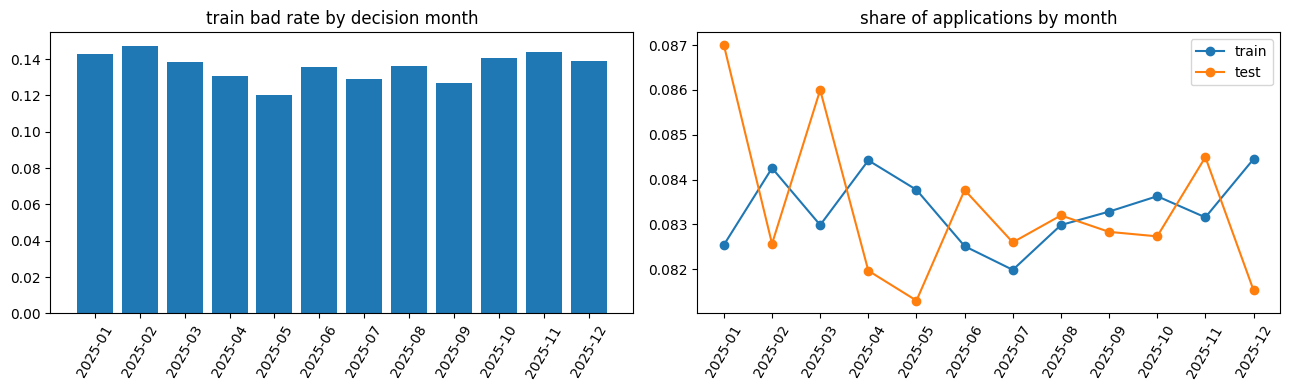

In [9]:
tr_raw, te_raw = T['train_applications'], T['test_applications']
print(f"train bad rate: {tr_raw['target'].mean():.4f}  (n_bad={tr_raw['target'].sum()})")
m = pl.concat([
    tr_raw.select(ym=pl.col('decision_datetime').dt.strftime('%Y-%m'), target='target', split=pl.lit('train')),
    te_raw.select(ym=pl.col('decision_datetime').dt.strftime('%Y-%m'), target=pl.lit(None, pl.Int64), split=pl.lit('test')),
])
tm = m.group_by('ym', 'split').agg(n=pl.len(), rate=pl.col('target').mean()).sort('ym')
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
p = tm.filter(pl.col('split') == 'train')
ax[0].bar(p['ym'], p['rate']); ax[0].set_title('train bad rate by decision month'); ax[0].tick_params(axis='x', rotation=60)
for s in ['train', 'test']:
    q = tm.filter(pl.col('split') == s)
    ax[1].plot(q['ym'], q['n'] / q['n'].sum(), marker='o', label=s)
ax[1].legend(); ax[1].set_title('share of applications by month'); ax[1].tick_params(axis='x', rotation=60)
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'target_time.png', dpi=90); plt.show()

#### Insights

> The bad rate is 13.6% and stays between 12% and 15% in every month of 2025. Train and test applications are interleaved over the same twelve months in the same 70/30 proportion, so the test set is a random sample of the same period rather than an out-of-time holdout.

> Stratified K-fold therefore mimics the leaderboard split, and no time-based validation is needed.

## Risk-Based Pricing

The interest rate takes only five values. If the lender priced loans from a risk grade, the rate itself carries that grade.

In [10]:
pricing = (tr_raw.group_by('annual_interest_rate')
           .agg(n=pl.len(), bad_rate=pl.col('target').mean()).sort('annual_interest_rate'))
print(pricing)
print('univariate KS of annual_interest_rate:', round(ks_score(tr_raw['target'], tr_raw['annual_interest_rate']), 4))

shape: (5, 3)
┌──────────────────────┬───────┬──────────┐
│ annual_interest_rate ┆ n     ┆ bad_rate │
│ ---                  ┆ ---   ┆ ---      │
│ f64                  ┆ u32   ┆ f64      │
╞══════════════════════╪═══════╪══════════╡
│ 0.16                 ┆ 12560 ┆ 0.054936 │
│ 0.2                  ┆ 29800 ┆ 0.106477 │
│ 0.24                 ┆ 22358 ┆ 0.177655 │
│ 0.28                 ┆ 4938  ┆ 0.303564 │
│ 0.32                 ┆ 344   ┆ 0.502907 │
└──────────────────────┴───────┴──────────┘
univariate KS of annual_interest_rate: 0.2301


#### Insights

> The bad rate rises monotonically from 5.5% at a 16% rate to 50% at a 32% rate, a univariate KS of 0.23. The offline analysis shows that the mean bureau score falls by about 40 points per tier, so the rate is largely a coarse copy of the bureau score. Inside bureau-score deciles the rate keeps only about 0.06 KS.

## Pre-Application Spending Burst

E-commerce orders are counted per customer per week before the decision, separately for bad and good loans. The shape of this curve sets the aggregation windows.

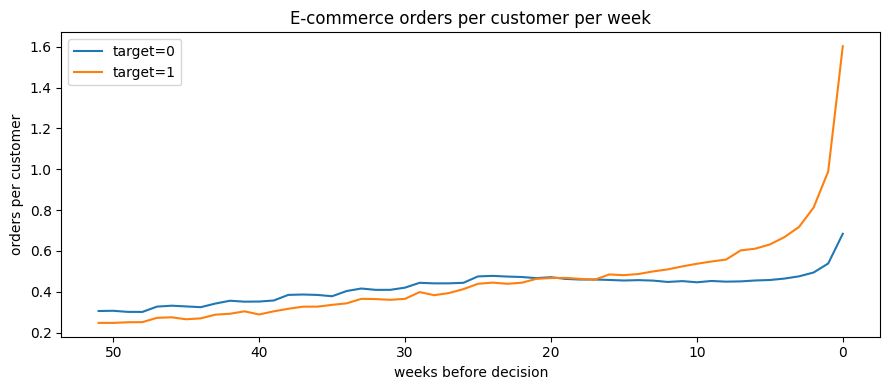

shape: (6, 4)
┌─────┬──────────┬──────────┬───────────────┐
│ wk  ┆ 1        ┆ 0        ┆ bad_over_good │
│ --- ┆ ---      ┆ ---      ┆ ---           │
│ i64 ┆ f64      ┆ f64      ┆ f64           │
╞═════╪══════════╪══════════╪═══════════════╡
│ 0   ┆ 1.603029 ┆ 0.684278 ┆ 2.34266       │
│ 1   ┆ 0.989376 ┆ 0.53874  ┆ 1.836463      │
│ 2   ┆ 0.81277  ┆ 0.494652 ┆ 1.643113      │
│ 3   ┆ 0.717682 ┆ 0.47584  ┆ 1.508241      │
│ 4   ┆ 0.668034 ┆ 0.464946 ┆ 1.436798      │
│ 5   ┆ 0.63185  ┆ 0.457871 ┆ 1.379974      │
└─────┴──────────┴──────────┴───────────────┘


In [11]:
o = (T['ecommerce_transactions'].join(tr_raw.select('customer_id', 'decision_datetime', 'target'), on='customer_id')
     .group_by('order_id').agg(pl.col('customer_id', 'decision_datetime', 'transaction_datetime', 'target').first())
     .with_columns(wk=((pl.col('decision_datetime') - pl.col('transaction_datetime')).dt.total_days() // 7)))
ncls = tr_raw.group_by('target').agg(ncust=pl.len())
wk = (o.filter(pl.col('wk') < 52).group_by('wk', 'target').agg(n=pl.len()).join(ncls, on='target')
      .with_columns(per=pl.col('n') / pl.col('ncust')).sort('wk'))
fig, ax = plt.subplots(figsize=(9, 4))
for k in (0, 1):
    q = wk.filter(pl.col('target') == k)
    ax.plot(q['wk'], q['per'], label=f'target={k}')
ax.invert_xaxis(); ax.set_xlabel('weeks before decision'); ax.set_ylabel('orders per customer'); ax.legend()
ax.set_title('E-commerce orders per customer per week')
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'ecom_burst.png', dpi=90); plt.show()
r = wk.pivot(on='target', index='wk', values='per').sort('wk').head(6)
print(r.with_columns(bad_over_good=pl.col('1') / pl.col('0')))

#### Insights

> Bad and good customers order at the same rate until about 16 weeks before the decision. After that, bad customers accelerate and reach 2.3 times the good rate in the final week. Lifetime totals dilute this signal, so the features use 7 to 90 day windows and an acceleration ratio against a 17-52 week baseline.

> Account behaviour shows the same pattern. The outflow-to-inflow ratio and low-balance days of bad customers deteriorate over the last 6 months, although they look slightly healthier than good customers a year earlier. Recent-versus-baseline deltas capture this.

## Lateness Severity

Repayment lateness has two sides: how often a customer is late, and how late the payment is when it is late. Days late among paid-late installments are compared between bad and good customers.

shape: (2, 7)
┌────────┬──────┬──────┬──────┬──────┬───────┬─────────────────────┐
│ target ┆ q10  ┆ q25  ┆ q50  ┆ q75  ┆ q90   ┆ n_late_installments │
│ ---    ┆ ---  ┆ ---  ┆ ---  ┆ ---  ┆ ---   ┆ ---                 │
│ i64    ┆ f64  ┆ f64  ┆ f64  ┆ f64  ┆ f64   ┆ u32                 │
╞════════╪══════╪══════╪══════╪══════╪═══════╪═════════════════════╡
│ 0      ┆ 30.0 ┆ 30.0 ┆ 31.0 ┆ 61.0 ┆ 91.0  ┆ 216447              │
│ 1      ┆ 30.0 ┆ 31.0 ┆ 61.0 ┆ 92.0 ┆ 123.0 ┆ 65188               │
└────────┴──────┴──────┴──────┴──────┴───────┴─────────────────────┘


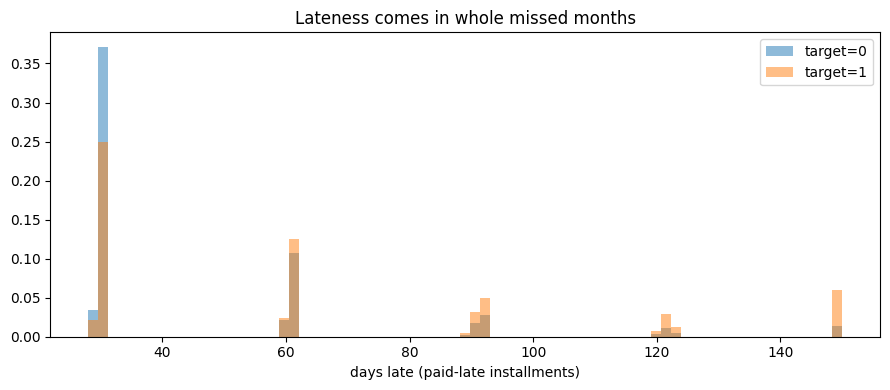

In [12]:
rp = (T['repayment_history'].join(tr_raw.select('customer_id', 'target'), on='customer_id')
      .filter(pl.col('amount_paid') >= pl.col('amount_due'))
      .with_columns(late_d=(pl.col('last_payment_datetime') - pl.col('due_date')).dt.total_days())
      .filter(pl.col('late_d') > 0))
print(rp.group_by('target').agg([pl.col('late_d').quantile(q).alias(f'q{int(q * 100)}') for q in (0.1, 0.25, 0.5, 0.75, 0.9)]
                                + [pl.len().alias('n_late_installments')]).sort('target'))
fig, ax = plt.subplots(figsize=(9, 4))
for k in (0, 1):
    ax.hist(rp.filter(pl.col('target') == k)['late_d'].clip(upper_bound=150), bins=75, density=True, alpha=0.5, label=f'target={k}')
ax.set_xlabel('days late (paid-late installments)'); ax.legend(); ax.set_title('Lateness comes in whole missed months')
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'late_severity.png', dpi=90); plt.show()

#### Insights

> Late payments cluster at about 30, 61 and 91 days. A late installment is a skipped month that is settled at a following due date. The median good customer catches up after one month and the median bad customer after two. Severity is therefore a separate measurement from the frequency features of version 1 (Spearman correlation about 0.63). `sv_maxdpd_mean_late` and `sv_share30_of_late` capture it.

> The offline residual analysis of the version 1 predictions also found smaller orthogonal signals: the first installment of each loan, the latest loan, the share of inflows that are not income, the bureau score trend over all pulls, and cancelled and night-time orders before the application. Each one moves the cross-fitted KS of version 1 by only 0.001 to 0.003. They are added together as the version 2 features.

## Table Coverage

Coverage of each auxiliary table is compared between splits, because a coverage mismatch would make the CV score unrepresentative.

In [13]:
split = pl.concat([tr_raw.select('customer_id', split=pl.lit('train')), te_raw.select('customer_id', split=pl.lit('test'))])
cov = []
for t in ['previous_applications', 'repayment_history', 'account_behavior', 'bureau_observations', 'ecommerce_transactions']:
    c = split.with_columns(has=pl.col('customer_id').is_in(T[t]['customer_id'].unique().implode()))
    cov.append(c.group_by('split').agg(pl.col('has').mean()).with_columns(table=pl.lit(t)))
print(pl.concat(cov).pivot(on='split', index='table', values='has'))

shape: (5, 3)
┌────────────────────────┬────────┬────────┐
│ table                  ┆ test   ┆ train  │
│ ---                    ┆ ---    ┆ ---    │
│ str                    ┆ f64    ┆ f64    │
╞════════════════════════╪════════╪════════╡
│ previous_applications  ┆ 0.7    ┆ 0.7    │
│ repayment_history      ┆ 0.6615 ┆ 0.6616 │
│ account_behavior       ┆ 0.7    ┆ 0.7    │
│ bureau_observations    ┆ 1.0    ┆ 1.0    │
│ ecommerce_transactions ┆ 1.0    ┆ 1.0    │
└────────────────────────┴────────┴────────┘


#### Insights

> Bureau and e-commerce data exist for every customer, while previous applications and account data exist for exactly 70% of customers in both splits (66% for repayment). The remaining 30% are thin-file customers, whose bad rate is lower (11.7% versus 14.4%).

> The offline audit also confirms that every auxiliary row is already dated before its customer's `decision_datetime`. There are no exact or near-duplicate customers across splits, and the hashed IDs carry no signal (KS < 0.01). The feature code still filters on the cutoff explicitly and is tested against injected future rows below.

---

# Feature Engineering <a name="4"></a>

---

Each auxiliary table is aggregated to one row per customer, and every builder filters on the customer's own cutoff (`decision_datetime`). Bureau reports must be *available* before the cutoff, account months must be *complete* before it, and e-commerce `order_total` is de-duplicated per order before it is summed, because it repeats on every item row.

## Feature Builders

The builders cover application and profile affordability ratios, bureau scores per provider and their change since earlier pulls, repayment lateness depth and active obligations, cash-flow levels and recent deltas, e-commerce recency and acceleration, and previous application outcomes and pricing.

In [14]:
DAY = 86400.0


def _days(a, b):
    return (pl.col(a) - pl.col(b)).dt.total_seconds() / DAY


def app_features(apps: pl.DataFrame, prof: pl.DataFrame) -> pl.DataFrame:
    d = apps.join(prof, on="customer_id", how="left")
    return d.select(
        "customer_id",
        "loan_amount", "annual_interest_rate", "proposed_monthly_installment", "loan_purpose",
        "age", "region", "employment_type", "employment_tenure_months", "declared_monthly_income",
        "dependents", "housing_status",
        decision_lag_h=(pl.col("decision_datetime") - pl.col("application_datetime")).dt.total_seconds() / 3600,
        app_hour=pl.col("application_datetime").dt.hour(),
        app_dow=pl.col("application_datetime").dt.weekday(),
        dti_declared=pl.col("proposed_monthly_installment") / pl.col("declared_monthly_income"),
        lti_declared=pl.col("loan_amount") / pl.col("declared_monthly_income"),
        tenure_over_age=pl.col("employment_tenure_months") / (pl.col("age") * 12),
        income_per_head=pl.col("declared_monthly_income") / (1 + pl.col("dependents")),
    )


def bureau_features(apps: pl.DataFrame, bureau: pl.DataFrame) -> pl.DataFrame:
    cut = apps.select("customer_id", sel_app=pl.col("application_id"), cutoff=pl.col("decision_datetime"))
    b = bureau.join(cut, on="customer_id").filter(pl.col("available_datetime") <= pl.col("cutoff"))
    b = b.with_columns(
        stale_d=_days("cutoff", "report_datetime"),
        delay_d=_days("available_datetime", "report_datetime"),
        is_sel=pl.col("application_id") == pl.col("sel_app"),
        prov=pl.col("bureau_provider").str.replace("Bureau_", "").str.to_lowercase(),
    )
    cur = b.filter("is_sel")
    num = ["score", "active_accounts", "outstanding_balance", "revolving_credit_limit",
           "revolving_outstanding_balance", "utilization", "inquiries_last_6m", "delinquent_accounts_last_12m"]
    agg = cur.group_by("customer_id").agg(
        bc_n_reports=pl.len(),
        bc_n_scored=pl.col("score").is_not_null().sum(),
        bc_score_mean=pl.col("score").mean(), bc_score_min=pl.col("score").min(),
        bc_score_max=pl.col("score").max(), bc_score_std=pl.col("score").std(),
        bc_active_max=pl.col("active_accounts").max(),
        bc_outstanding_max=pl.col("outstanding_balance").max(),
        bc_revlimit_max=pl.col("revolving_credit_limit").max(),
        bc_revbal_max=pl.col("revolving_outstanding_balance").max(),
        bc_util_max=pl.col("utilization").max(), bc_util_mean=pl.col("utilization").mean(),
        bc_inq_max=pl.col("inquiries_last_6m").max(), bc_inq_mean=pl.col("inquiries_last_6m").mean(),
        bc_delinq_max=pl.col("delinquent_accounts_last_12m").max(),
        bc_delinq_sum=pl.col("delinquent_accounts_last_12m").sum(),
        bc_stale_mean=pl.col("stale_d").mean(), bc_stale_max=pl.col("stale_d").max(),
        bc_delay_mean=pl.col("delay_d").mean(),
    )
    piv = cur.pivot(on="prov", index="customer_id", values=["score", "utilization", "inquiries_last_6m",
                                                            "delinquent_accounts_last_12m", "outstanding_balance"],
                    aggregate_function="first")
    piv = piv.rename({c: "bp_" + c.replace("inquiries_last_6m", "inq").replace("delinquent_accounts_last_12m", "delinq")
                      .replace("outstanding_balance", "out").replace("utilization", "util")
                      for c in piv.columns if c != "customer_id"})
    # history: bureau pulled at earlier (previous) applications
    hist = b.filter(~pl.col("is_sel")).group_by("customer_id").agg(
        bh_n_pulls=pl.col("application_id").n_unique(),
        bh_score_mean=pl.col("score").mean(), bh_score_min=pl.col("score").min(),
        bh_delinq_max=pl.col("delinquent_accounts_last_12m").max(),
        bh_inq_mean=pl.col("inquiries_last_6m").mean(),
        bh_last_score=pl.col("score").sort_by("report_datetime").drop_nulls().last(),
        bh_last_outstanding=pl.col("outstanding_balance").sort_by("report_datetime").last(),
        bh_pulls_180d=pl.col("application_id").filter(pl.col("stale_d") <= 180).n_unique(),
    )
    out = agg.join(piv, on="customer_id", how="left").join(hist, on="customer_id", how="left")
    return out.with_columns(
        bh_score_delta=pl.col("bc_score_mean") - pl.col("bh_last_score"),
        bh_outstanding_delta=pl.col("bc_outstanding_max") - pl.col("bh_last_outstanding"),
    )


def repayment_features(apps: pl.DataFrame, rep: pl.DataFrame, prev: pl.DataFrame) -> pl.DataFrame:
    cut = apps.select("customer_id", cutoff=pl.col("decision_datetime"))
    r = rep.join(cut, on="customer_id").filter(pl.col("due_date") <= pl.col("cutoff"))
    r = r.with_columns(
        age_d=_days("cutoff", "due_date"),
        unpaid=pl.col("amount_due") - pl.col("amount_paid"),
        late_d=pl.when(pl.col("amount_paid") >= pl.col("amount_due")).then(_days("last_payment_datetime", "due_date")),
    )
    w = lambda days: pl.col("age_d") <= days  # noqa: E731
    agg = r.group_by("customer_id").agg(
        rp_n_loans=pl.col("loan_id").n_unique(), rp_n_inst=pl.len(),
        rp_maxdpd_max=pl.col("max_days_past_due").max(), rp_maxdpd_mean=pl.col("max_days_past_due").mean(),
        rp_n_dpd1=(pl.col("max_days_past_due") > 0).sum(), rp_n_dpd30=(pl.col("max_days_past_due") >= 30).sum(),
        rp_n_dpd60=(pl.col("max_days_past_due") >= 60).sum(), rp_n_dpd90=(pl.col("max_days_past_due") >= 90).sum(),
        rp_frac_dpd1=(pl.col("max_days_past_due") > 0).mean(), rp_frac_dpd30=(pl.col("max_days_past_due") >= 30).mean(),
        rp_cur_dpd_max=pl.col("days_past_due").max(), rp_n_unpaid=(pl.col("unpaid") > 0).sum(),
        rp_unpaid_amt=pl.col("unpaid").sum(),
        rp_paid_ratio=pl.col("amount_paid").sum() / pl.col("amount_due").sum(),
        rp_late_mean=pl.col("late_d").mean(), rp_late_max=pl.col("late_d").max(),
        rp_maxdpd_6m=pl.col("max_days_past_due").filter(w(183)).max(),
        rp_maxdpd_12m=pl.col("max_days_past_due").filter(w(365)).max(),
        rp_frac_dpd1_6m=(pl.col("max_days_past_due") > 0).filter(w(183)).mean(),
        rp_late_mean_6m=pl.col("late_d").filter(w(183)).mean(),
        rp_maxdpd_last3=pl.col("max_days_past_due").sort_by("due_date", "loan_id").tail(3).max(),
        rp_days_since_delinq=pl.col("age_d").filter(pl.col("max_days_past_due") > 0).min(),
        rp_days_since_due=pl.col("age_d").min(),
    )
    # active loans: fewer installments observed than contracted term -> remaining obligation
    loans = r.group_by("loan_id").agg(customer_id=pl.col("customer_id").first(), n_seen=pl.len(),
                                      inst=pl.col("amount_due").first())
    loans = loans.join(prev.select("loan_id", "term_months"), on="loan_id", how="left").with_columns(
        remaining=(pl.col("term_months") - pl.col("n_seen")).clip(lower_bound=0))
    act = loans.group_by("customer_id").agg(
        rp_n_active=(pl.col("remaining") > 0).sum(),
        rp_active_inst=pl.col("inst").filter(pl.col("remaining") > 0).sum(),
        rp_remaining_oblig=(pl.col("remaining") * pl.col("inst")).sum(),
    )
    return agg.join(act, on="customer_id", how="left")


def account_features(apps: pl.DataFrame, acc: pl.DataFrame) -> pl.DataFrame:
    cut = apps.select("customer_id", cutoff=pl.col("decision_datetime"))
    a = acc.join(cut, on="customer_id").filter(
        pl.col("month").dt.offset_by("1mo").cast(pl.Datetime) <= pl.col("cutoff")).sort("customer_id", "month")
    a = a.with_columns(mago=pl.col("month").rank("dense", descending=True).over("customer_id"))
    l3 = pl.col("mago") <= 3
    out = a.group_by("customer_id").agg(
        ac_n_months=pl.len(),
        ac_inflow_mean=pl.col("inflows").mean(), ac_outflow_mean=pl.col("outflows").mean(),
        ac_income_mean=pl.col("income_like_credits").mean(), ac_income_std=pl.col("income_like_credits").std(),
        ac_income_min=pl.col("income_like_credits").min(),
        ac_avgbal_mean=pl.col("average_balance").mean(), ac_minbal_min=pl.col("minimum_balance").min(),
        ac_minbal_mean=pl.col("minimum_balance").mean(),
        ac_lowdays_mean=pl.col("low_balance_days").mean(), ac_lowdays_max=pl.col("low_balance_days").max(),
        ac_frac_zero_min=(pl.col("minimum_balance") == 0).mean(),
        ac_net_flow_mean=(pl.col("inflows") - pl.col("outflows")).mean(),
        ac_out_in_ratio=pl.col("outflows").sum() / pl.col("inflows").sum(),
        ac_income_l3=pl.col("income_like_credits").filter(l3).mean(),
        ac_avgbal_l3=pl.col("average_balance").filter(l3).mean(),
        ac_lowdays_l3=pl.col("low_balance_days").filter(l3).mean(),
        ac_out_in_l3=pl.col("outflows").filter(l3).sum() / pl.col("inflows").filter(l3).sum(),
        ac_last_close=pl.col("closing_balance").last(),
        ac_out_in_b=pl.col("outflows").filter(pl.col("mago").is_between(7, 12)).sum()
        / pl.col("inflows").filter(pl.col("mago").is_between(7, 12)).sum(),
        ac_lowdays_b=pl.col("low_balance_days").filter(pl.col("mago").is_between(7, 12)).mean(),
        ac_avgbal_b=pl.col("average_balance").filter(pl.col("mago").is_between(7, 12)).mean(),
        ac_out_in_l1=(pl.col("outflows") / pl.col("inflows")).filter(pl.col("mago") == 1).first(),
        ac_close_slope=pl.cov(pl.col("mago").cast(pl.Float64), pl.col("closing_balance").cast(pl.Float64))
        / pl.col("mago").cast(pl.Float64).var() * -1,
    )
    return out.with_columns(
        ac_income_cv=pl.col("ac_income_std") / pl.col("ac_income_mean"),
        ac_income_trend=pl.col("ac_income_l3") / pl.col("ac_income_mean"),
        ac_bal_trend=pl.col("ac_avgbal_l3") / (pl.col("ac_avgbal_mean") + 1),
        ac_out_in_delta=pl.col("ac_out_in_l3") - pl.col("ac_out_in_b"),
        ac_lowdays_delta=pl.col("ac_lowdays_l3") - pl.col("ac_lowdays_b"),
        ac_bal_delta=(pl.col("ac_avgbal_l3") + 1) / (pl.col("ac_avgbal_b") + 1),
    )


def ecommerce_features(apps: pl.DataFrame, ec: pl.DataFrame) -> pl.DataFrame:
    cut = apps.select("customer_id", cutoff=pl.col("decision_datetime"))
    e = ec.join(cut, on="customer_id").filter(pl.col("transaction_datetime") <= pl.col("cutoff"))
    e = e.with_columns(age_d=_days("cutoff", "transaction_datetime"), done=pl.col("order_status") == "completed")
    # order level: order_total repeats on each item -> dedupe before aggregating
    o = e.group_by("order_id").agg(pl.col("customer_id", "age_d", "order_total", "payment_method", "done").first())
    agg = o.group_by("customer_id").agg(
        ec_n_orders=pl.len(), ec_cancel_rate=1 - pl.col("done").mean(),
        ec_spend=pl.col("order_total").filter("done").sum(),
        ec_aov=pl.col("order_total").filter("done").mean(),
        ec_recency_d=pl.col("age_d").min(), ec_tenure_d=pl.col("age_d").max(),
        ec_orders_7d=(pl.col("age_d") <= 7).sum(), ec_orders_14d=(pl.col("age_d") <= 14).sum(),
        ec_orders_30d=(pl.col("age_d") <= 30).sum(), ec_orders_60d=(pl.col("age_d") <= 60).sum(),
        ec_orders_90d=(pl.col("age_d") <= 90).sum(),
        ec_base_wk=((pl.col("age_d") > 120) & (pl.col("age_d") <= 365)).sum()
        / ((pl.col("age_d").max().clip(upper_bound=365) - 120).clip(lower_bound=7) / 7),
        ec_spend_30d=pl.col("order_total").filter(pl.col("done") & (pl.col("age_d") <= 30)).sum(),
        ec_spend_90d=pl.col("order_total").filter(pl.col("done") & (pl.col("age_d") <= 90)).sum(),
        ec_cancel_90d=(~pl.col("done")).filter(pl.col("age_d") <= 90).sum(),
        **{f"ec_pm_{m}": (pl.col("payment_method") == m).mean()
           for m in ["COD", "e_wallet", "bank_transfer", "debit_card", "credit_card"]},
    )
    cat = (e.filter("done").group_by("customer_id", "product_category").agg(s=pl.col("item_total").sum())
           .with_columns(s=pl.col("s") / pl.col("s").sum().over("customer_id"))
           .pivot(on="product_category", index="customer_id", values="s"))
    cat = cat.rename({c: f"ec_cat_{c}" for c in cat.columns if c != "customer_id"})
    out = agg.join(cat, on="customer_id", how="left").with_columns(
        ec_spend_per_month=pl.col("ec_spend") / (pl.col("ec_tenure_d") / 30.4 + 1),
        ec_spend_90d_ratio=pl.col("ec_spend_90d") / 3 / (pl.col("ec_spend") / (pl.col("ec_tenure_d") / 30.4 + 1) + 1),
    )
    return out.with_columns(
        pl.col("^ec_cat_.*$").fill_null(0),
        ec_accel_30d=(pl.col("ec_orders_30d") / (30 / 7)) / (pl.col("ec_base_wk") + 0.1),
        ec_accel_90d=(pl.col("ec_orders_90d") / (90 / 7)) / (pl.col("ec_base_wk") + 0.1),
    )


def prev_features(apps: pl.DataFrame, prev: pl.DataFrame) -> pl.DataFrame:
    cut = apps.select("customer_id", cutoff=pl.col("decision_datetime"), cur_rate=pl.col("annual_interest_rate"),
                      cur_amt=pl.col("loan_amount"))
    p = prev.join(cut, on="customer_id").filter(pl.col("decision_datetime") <= pl.col("cutoff"))
    p = p.with_columns(age_d=_days("cutoff", "application_datetime"))
    out = p.group_by("customer_id").agg(
        pv_n=pl.len(), pv_n_appr=(pl.col("decision") == "approved").sum(),
        pv_n_rej=(pl.col("decision") == "rejected").sum(), pv_n_canc=(pl.col("decision") == "cancelled").sum(),
        pv_rej_rate=(pl.col("decision") == "rejected").mean(),
        pv_days_since_last=pl.col("age_d").min(), pv_days_since_first=pl.col("age_d").max(),
        pv_n_90d=(pl.col("age_d") <= 90).sum(), pv_n_180d=(pl.col("age_d") <= 180).sum(),
        pv_rej_365d=((pl.col("decision") == "rejected") & (pl.col("age_d") <= 365)).sum(),
        pv_rate_mean=pl.col("annual_interest_rate").mean(), pv_rate_max=pl.col("annual_interest_rate").max(),
        pv_rate_last=pl.col("annual_interest_rate").sort_by("application_datetime").drop_nulls().last(),
        pv_appr_ratio=(pl.col("approved_amount") / pl.col("requested_amount")).mean(),
        pv_req_mean=pl.col("requested_amount").mean(), pv_appr_sum=pl.col("approved_amount").sum(),
        pv_appr_max=pl.col("approved_amount").max(),
        pv_last_decision_rej=(pl.col("decision").sort_by("application_datetime").last() == "rejected"),
        cur_rate=pl.col("cur_rate").first(), cur_amt=pl.col("cur_amt").first(),
    )
    return out.with_columns(
        pv_rate_delta=pl.col("cur_rate") - pl.col("pv_rate_last"),
        pv_amt_vs_max=pl.col("cur_amt") / pl.col("pv_appr_max"),
        pv_last_decision_rej=pl.col("pv_last_decision_rej").cast(pl.Int8),
    ).drop("cur_rate", "cur_amt")


def v2_features(apps: pl.DataFrame, tables: dict) -> pl.DataFrame:
    cut = apps.select("customer_id", "application_id", cutoff=pl.col("decision_datetime"),
                      inst_new=pl.col("proposed_monthly_installment"), amt_new=pl.col("loan_amount"))
    # bureau: score trend/range over every pull, newest report, delinquency over all pulls, external inquiries
    b = tables["bureau_observations"].join(cut.select("customer_id", "cutoff", sel=pl.col("application_id")), on="customer_id")
    b = b.filter(pl.col("available_datetime") <= pl.col("cutoff")).with_columns(
        age_d=_days("cutoff", "report_datetime"), is_sel=pl.col("application_id") == pl.col("sel"))
    bz = b.group_by("customer_id").agg(
        bz_trend=pl.cov(pl.col("age_d"), pl.col("score")) / pl.col("age_d").var() * -365,
        bz_range=pl.col("score").max() - pl.col("score").min(),
        bz_newest=pl.col("score").sort_by("report_datetime").drop_nulls().last(),
        bz_delinq_all_mean=pl.col("delinquent_accounts_last_12m").mean(),
        bz_active_trend=pl.col("active_accounts").filter("is_sel").mean()
        - pl.col("active_accounts").filter(~pl.col("is_sel")).mean(),
        bz_inq_cur=pl.col("inquiries_last_6m").filter("is_sel").mean(),
    )
    p = tables["previous_applications"].join(cut, on="customer_id").filter(pl.col("decision_datetime") <= pl.col("cutoff"))
    own6 = p.filter(_days("cutoff", "application_datetime") <= 183).group_by("customer_id").agg(own6=pl.len())
    bz = bz.join(own6, on="customer_id", how="left").with_columns(
        bz_inq_external=pl.col("bz_inq_cur") - pl.col("own6").fill_null(0)).drop("bz_inq_cur", "own6")
    # previous approvals: tenor mix, recency, recent approved volume, remaining scheduled obligation
    ap = p.filter(pl.col("decision") == "approved").with_columns(
        age_d=_days("cutoff", "decision_datetime"),
        rem=(pl.col("term_months") - (_days("cutoff", "decision_datetime") / 30.44).floor()).clip(lower_bound=0))
    ob = ap.group_by("customer_id").agg(
        ob_term_mean=pl.col("term_months").mean(), ob_days_since_appr=pl.col("age_d").min(),
        ob_amt_90d=pl.col("approved_amount").filter(pl.col("age_d") <= 90).sum(),
        ob_remaining=(pl.col("scheduled_monthly_installment") * pl.col("rem")).sum(),
        amt_new=pl.col("amt_new").first(),
    ).with_columns(ob_amt_vs_last=pl.col("amt_new") / (pl.col("ob_amt_90d") + 1e6)).drop("amt_new")
    # repayment: first installment, latest loan, 1-29 dpd share, recent trend, streaks, severity when late
    r = tables["repayment_history"].join(cut.select("customer_id", "cutoff"), on="customer_id")
    # loan_id breaks due_date ties between concurrent loans -> deterministic order
    r = r.filter(pl.col("due_date") <= pl.col("cutoff")).sort("customer_id", "due_date", "loan_id").with_columns(
        late=(pl.col("max_days_past_due") > 0).cast(pl.Int32),
        paid=pl.col("amount_paid") >= pl.col("amount_due"),
        late_d=_days("last_payment_datetime", "due_date"),
        k=pl.col("due_date").rank("ordinal").over("loan_id"),
        loan_start=pl.col("due_date").min().over("loan_id"))
    # streak of consecutive late installments within one loan (concurrent loans interleave in time)
    r = r.with_columns(run=(pl.col("late") != pl.col("late").shift(1)).fill_null(True).cum_sum().over("loan_id"))
    streak = (r.filter(pl.col("late") == 1).group_by("customer_id", "loan_id", "run").agg(n=pl.len())
              .group_by("customer_id").agg(rq_streak_max=pl.col("n").max()))
    last = (r.filter(pl.col("loan_start") == pl.col("loan_start").max().over("customer_id"))
            .group_by("customer_id").agg(rq_lastloan_late=pl.col("late").mean(), rq_lastloan_maxdpd=pl.col("max_days_past_due").max()))
    dpd, late = pl.col("max_days_past_due"), pl.col("max_days_past_due") > 0
    rq = r.group_by("customer_id").agg(
        rq_first_inst_late=pl.col("late").filter(pl.col("k") == 1).mean(),
        rq_frac_1_29=(late & (dpd < 30)).mean(),
        rq_late_trend=pl.col("late").tail(6).mean() - pl.col("late").head(pl.len() - 6).mean(),
        sv_maxdpd_mean_late=dpd.filter(late).mean(),
        sv_late_d_mean=pl.col("late_d").filter(pl.col("paid") & (pl.col("late_d") > 0)).mean(),
        sv_share30_of_late=(dpd >= 30).sum() / late.sum(),
        sv_unpaid_of_late=(~pl.col("paid") & late).sum() / late.sum(),
    ).join(streak, on="customer_id", how="left").join(last, on="customer_id", how="left")
    # account: non-income inflows, recent outflows, worst free cash flow, new installment vs free cash / min balance
    a = tables["account_behavior"].join(cut.select("customer_id", "cutoff", "inst_new"), on="customer_id")
    a = a.filter(pl.col("month").dt.offset_by("1mo").cast(pl.Datetime) <= pl.col("cutoff")).with_columns(
        l3=pl.col("month").rank("dense", descending=True).over("customer_id") <= 3,
        free=pl.col("inflows") - pl.col("outflows"))
    cf = a.group_by("customer_id").agg(
        cf_nonincome_share=1 - pl.col("income_like_credits").sum() / pl.col("inflows").sum(),
        cf_nonincome_l3=1 - pl.col("income_like_credits").filter("l3").sum() / pl.col("inflows").filter("l3").sum(),
        cf_out_l3=pl.col("outflows").filter("l3").mean(), cf_free_min=pl.col("free").min(),
        cf_free_l3=pl.col("free").filter("l3").mean(), cf_inc_l3=pl.col("income_like_credits").filter("l3").mean(),
        cf_minbal_l3=pl.col("minimum_balance").filter("l3").min(), inst_new=pl.col("inst_new").first(),
    ).with_columns(
        cf_inst_to_free=pl.col("inst_new") / (pl.col("cf_free_l3").clip(lower_bound=0) + 1e5),
        cf_out_to_inc_l3=pl.col("cf_out_l3") / (pl.col("cf_inc_l3") + 1e5),
        cf_inst_to_minbal=pl.col("inst_new") / (pl.col("cf_minbal_l3") + 1e5),
    ).drop("inst_new", "cf_free_l3", "cf_inc_l3")
    # e-commerce: cancellations, night share, basket size, AOV shift, tightest gap, smooth recency-weighted counts
    e = tables["ecommerce_transactions"].join(cut.select("customer_id", "cutoff"), on="customer_id")
    e = e.filter(pl.col("transaction_datetime") <= pl.col("cutoff"))
    o = e.group_by("order_id").agg(pl.col("customer_id", "cutoff", "transaction_datetime", "order_total", "order_status").first(),
                                   n_items=pl.len())
    o = o.with_columns(age_d=_days("cutoff", "transaction_datetime"), done=pl.col("order_status") == "completed",
                       night=pl.col("transaction_datetime").dt.hour() < 5)
    r28, old = pl.col("age_d") <= 28, pl.col("age_d") > 182
    ec = o.group_by("customer_id").agg(
        ec2_base=(old & (pl.col("age_d") <= 730)).sum()
        / ((pl.col("age_d").max().clip(upper_bound=730) - 182).clip(lower_bound=14) / 7),
        ec2_cancel_28=(~pl.col("done")).filter(r28).sum(),
        ec2_night_share_90=pl.col("night").filter(pl.col("age_d") <= 90).mean(),
        ec2_items_per_order_28=pl.col("n_items").filter(r28).mean(),
        ec2_aov_28=pl.col("order_total").filter(pl.col("done") & r28).mean(),
        ec2_aov_old=pl.col("order_total").filter(pl.col("done") & old).mean(),
        ec2_gap_min_28=pl.col("age_d").filter(r28).sort().diff().min(),
        **{f"ec2_ewm{t}": (-pl.col("age_d") / t).exp().sum() for t in (7, 28, 56)},
    ).with_columns(
        ec2_aov_shift=pl.col("ec2_aov_28") / pl.col("ec2_aov_old"),
        ec2_ewm7_rel=pl.col("ec2_ewm7") / (pl.col("ec2_base") + 0.05),
        ec2_ewm28_exc=pl.col("ec2_ewm28") - pl.col("ec2_base") * 4,
        ec2_ewm56_rel=pl.col("ec2_ewm56") / (pl.col("ec2_base") * 8 + 0.05),
    ).drop("ec2_aov_28", "ec2_aov_old", "ec2_ewm7", "ec2_ewm28", "ec2_ewm56")
    out = cut.select("customer_id")
    for part in (bz, ob, rq, cf, ec):
        out = out.join(part, on="customer_id", how="left")
    return out


def build_all(tables: dict) -> pl.DataFrame:
    tr = tables["train_applications"].with_columns(is_train=pl.lit(1))
    te = tables["test_applications"].with_columns(target=pl.lit(None, pl.Int64), is_train=pl.lit(0))
    apps = pl.concat([tr, te], how="diagonal_relaxed")
    f = apps.select("application_id", "customer_id", "decision_datetime", "target", "is_train")
    for part in [
        app_features(apps, tables["customer_profiles"]),
        bureau_features(apps, tables["bureau_observations"]),
        repayment_features(apps, tables["repayment_history"], tables["previous_applications"]),
        account_features(apps, tables["account_behavior"]),
        ecommerce_features(apps, tables["ecommerce_transactions"]),
        prev_features(apps, tables["previous_applications"]),
        v2_features(apps, tables),
    ]:
        f = f.join(part, on="customer_id", how="left")
    # cross-table ratios: the real affordability picture
    f = f.with_columns(
        has_history=pl.col("pv_n").is_not_null().cast(pl.Int8),
        dti_verified=pl.col("proposed_monthly_installment") / pl.col("ac_income_mean"),
        dti_total=(pl.col("proposed_monthly_installment") + pl.col("rp_active_inst").fill_null(0))
        / pl.col("declared_monthly_income"),
        income_verif_ratio=pl.col("ac_income_mean") / pl.col("declared_monthly_income"),
        debt_to_income=pl.col("bc_outstanding_max") / pl.col("declared_monthly_income"),
        inst_to_avgbal=pl.col("proposed_monthly_installment") / (pl.col("ac_avgbal_mean") + 1),
        ecspend_to_income=pl.col("ec_spend_per_month") / pl.col("declared_monthly_income"),
    )
    return f

In [15]:
t0 = time.time()
feats = build_all(T)
assert feats['application_id'].n_unique() == feats.height == T['train_applications'].height + T['test_applications'].height
print(f'feature matrix {feats.shape} built in {time.time() - t0:.1f}s')

feature matrix (100000, 219) built in 10.5s


## Leakage Injection Test

Fake rows dated after each customer's cutoff are appended to all five dated tables, using extreme values: a DPD of 999, a cancelled 1e9 order, a score of 300 with 99 inquiries, the incomplete decision month with zero income, and an approved 1e9 loan decided after the cutoff. If any feature changes, the cutoff logic is broken and the notebook stops. The comparison allows a 1e-9 relative tolerance, because sums of floats can differ in the last bits when the row order changes.

In [16]:
apps_all = pl.concat([T['train_applications'], T['test_applications']], how='diagonal_relaxed')
fut = apps_all.select('customer_id', cut='decision_datetime').sample(2000, seed=1)
def first_rows(t):
    return T[t].join(fut, on='customer_id').group_by('customer_id').first()
after = pl.col('cut') + pl.duration(days=5)
inj = {
    'repayment_history': first_rows('repayment_history').with_columns(
        due_date=after, max_days_past_due=pl.lit(999), days_past_due=pl.lit(999)),
    'ecommerce_transactions': first_rows('ecommerce_transactions').with_columns(
        transaction_datetime=pl.col('cut') + pl.duration(hours=1), order_id=pl.lit('O_FAKE') + pl.col('customer_id'),
        order_total=pl.lit(10**9), order_status=pl.lit('cancelled')),
    'bureau_observations': first_rows('bureau_observations').with_columns(
        available_datetime=after, score=pl.lit(300.0), inquiries_last_6m=pl.lit(99)),
    'account_behavior': first_rows('account_behavior').with_columns(
        month=pl.col('cut').dt.truncate('1mo').cast(pl.Date), outflows=pl.lit(10**10), income_like_credits=pl.lit(0)),
    'previous_applications': first_rows('previous_applications').with_columns(
        application_datetime=pl.col('cut') - pl.duration(hours=1), decision_datetime=after, decision=pl.lit('approved'),
        approved_amount=pl.lit(10**9), term_months=pl.lit(6),
        application_id=pl.lit('A_FAKE') + pl.col('customer_id'), loan_id=pl.lit('L_FAKE') + pl.col('customer_id')),
}
T_leak = dict(T)
for t, extra in inj.items():
    T_leak[t] = pl.concat([T[t], extra.select(T[t].columns)], how='vertical_relaxed')
f_leak = build_all(T_leak).sort('application_id')
f_ref = feats.sort('application_id')
num_cols = [c for c, d in f_ref.schema.items() if d.is_numeric()]
def moved(c):
    a, b = (f[c].cast(pl.Float64).fill_nan(None).fill_null(-7.0).to_numpy() for f in (f_ref, f_leak))
    return not np.allclose(a, b, rtol=1e-9, atol=1e-9)
changed = [c for c in num_cols if moved(c)]
assert not changed, f'cutoff leak in {changed}'
print(f'leakage injection test passed: none of {len(num_cols)} numeric features moved')
del T_leak, f_leak, f_ref
_ = gc.collect()

leakage injection test passed: none of 212 numeric features moved


## Feature Diagnostics

Every numeric feature is scored by univariate KS against the target and by PSI between train and test. A high-KS feature that also drifts would split public and private scores, so both are checked together.

In [17]:
ID_COLS  = ['application_id', 'customer_id', 'decision_datetime', 'target', 'is_train']
CAT_COLS = ['loan_purpose', 'region', 'employment_type', 'housing_status']
FEATURES = sorted(c for c in feats.columns if c not in ID_COLS)
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]

tr_f, te_f = feats.filter(pl.col('is_train') == 1), feats.filter(pl.col('is_train') == 0)
y = tr_f['target'].to_numpy()
diag = pl.DataFrame({
    'feature': NUM_COLS,
    'ks': [ks_nan(y, tr_f[c].cast(pl.Float64).to_numpy()) for c in NUM_COLS],
    'psi': [psi(tr_f[c].cast(pl.Float64).to_numpy(), te_f[c].cast(pl.Float64).to_numpy()) for c in NUM_COLS],
    'coverage': [1 - tr_f[c].null_count() / tr_f.height for c in NUM_COLS],
}).sort('ks', descending=True)
V2_PREFIX = ('bz_', 'ob_', 'rq_', 'sv_', 'cf_', 'ec2_')
V1_FEATURES = [c for c in FEATURES if not c.startswith(V2_PREFIX)]
V2_FEATURES = [c for c in FEATURES if c.startswith(V2_PREFIX)]
with pl.Config(tbl_rows=25, float_precision=4):
    print(diag.head(25))
    print('version 2 features:')
    print(diag.filter(pl.col('feature').is_in(V2_FEATURES)).head(15))
print('max PSI over all features:', round(diag['psi'].max(), 5))
print(f'{len(FEATURES)} features ({len(CAT_COLS)} categorical), {len(V2_FEATURES)} new in version 2')

shape: (25, 4)
┌─────────────────────┬────────┬────────┬──────────┐
│ feature             ┆ ks     ┆ psi    ┆ coverage │
│ ---                 ┆ ---    ┆ ---    ┆ ---      │
│ str                 ┆ f64    ┆ f64    ┆ f64      │
╞═════════════════════╪════════╪════════╪══════════╡
│ rp_frac_dpd1        ┆ 0.3183 ┆ 0.0002 ┆ 0.6616   │
│ ec2_ewm28_exc       ┆ 0.3099 ┆ 0.0006 ┆ 1.0000   │
│ ec_accel_30d        ┆ 0.3090 ┆ 0.0002 ┆ 1.0000   │
│ rp_maxdpd_mean      ┆ 0.3086 ┆ 0.0001 ┆ 0.6616   │
│ ec2_ewm56_rel       ┆ 0.3084 ┆ 0.0003 ┆ 1.0000   │
│ rp_frac_dpd30       ┆ 0.3060 ┆ 0.0006 ┆ 0.6616   │
│ ec2_ewm7_rel        ┆ 0.3041 ┆ 0.0004 ┆ 1.0000   │
│ ec_accel_90d        ┆ 0.3019 ┆ 0.0007 ┆ 1.0000   │
│ rp_late_mean        ┆ 0.2982 ┆ 0.0001 ┆ 0.6596   │
│ ec_spend_30d        ┆ 0.2912 ┆ 0.0002 ┆ 1.0000   │
│ ec_orders_14d       ┆ 0.2911 ┆ 0.0003 ┆ 1.0000   │
│ ec_orders_30d       ┆ 0.2884 ┆ 0.0002 ┆ 1.0000   │
│ ec_spend_90d        ┆ 0.2858 ┆ 0.0000 ┆ 1.0000   │
│ ec_orders_60d       ┆ 0.2839 

#### Insights

> The strongest single features are repayment lateness (`rp_frac_dpd1`, KS about 0.32), e-commerce acceleration (`ec_accel_30d`, about 0.31) and the mean bureau score (about 0.25). The first two are nearly orthogonal to the bureau score and keep about 0.30 KS inside score deciles, which is why combining sources gives a large lift. A rank average of nine such features with no training already reaches a KS of about 0.41.

> The version 2 features have univariate KS up to about 0.27, but they were chosen for what they add on top of version 1, not for their stand-alone KS. The maximum PSI is far below the usual 0.1 alert level, so no feature needs to be dropped for stability.

## Additivity of Risk Signals

The bad rate is tabulated over quintiles of two signal families, with missing values as a sixth bin. If the lines are parallel on the log-odds scale, the families add up and deep interactions are not needed, which favours shallow trees.

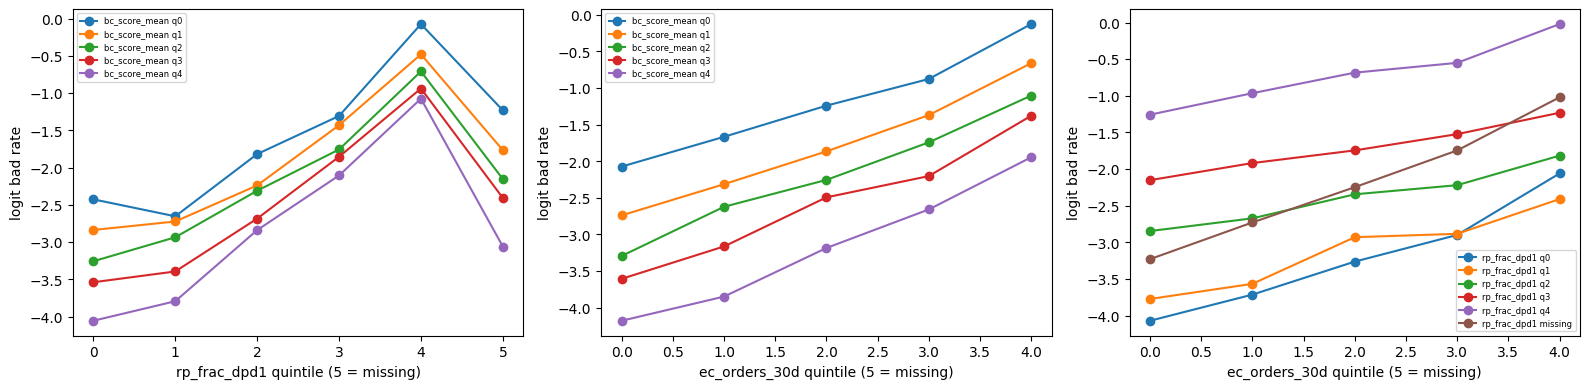

In [18]:
def logit_lines(ax, a, b, q=5):
    d = tr_f.select(a, b, 'target').with_columns(
        qa=(pl.col(a).rank('ordinal') * q // (pl.col(a).count() + 1)).fill_null(q),
        qb=(pl.col(b).rank('ordinal') * q // (pl.col(b).count() + 1)).fill_null(q))
    g = (d.group_by('qa', 'qb').agg(n=pl.len(), bad=pl.col('target').sum()).filter(pl.col('n') >= 100)
          .with_columns(logit=((pl.col('bad') + 1) / (pl.col('n') - pl.col('bad') + 1)).log()).sort('qa', 'qb'))
    for k in range(q + 1):
        s = g.filter(pl.col('qb') == k)
        if s.height:
            ax.plot(s['qa'], s['logit'], 'o-', label=f'{b} q{k}' if k < q else f'{b} missing')
    ax.set_xlabel(f'{a} quintile ({q} = missing)'); ax.set_ylabel('logit bad rate'); ax.legend(fontsize=6)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for i, (a, b) in enumerate([('rp_frac_dpd1', 'bc_score_mean'), ('ec_orders_30d', 'bc_score_mean'), ('ec_orders_30d', 'rp_frac_dpd1')]):
    logit_lines(ax[i], a, b)
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'additivity.png', dpi=90); plt.show()

#### Insights

> The lines are close to parallel, so repayment, e-commerce and bureau risk combine additively in log-odds. The offline interaction test confirms that the version 1 model already captured the remaining non-additive part: no pair of families left more than noise-level structure in its residuals. The main departure is that e-commerce is steeper for thin-file customers (the missing repayment line), and a depth-3 tree can still express that. Shallow variants with stronger regularisation are therefore added next to the deep version 1 settings.

---

# Validation Strategy <a name="5"></a>

---

Because the test set is a random sample of the training period, repeated stratified 5-fold CV is used. Every model reports per-fold KS, the out-of-fold (OOF) KS and its spread. The OOF predictions also drive a public/private split simulation that estimates how far the two leaderboards can disagree from sampling noise alone.

In [19]:
X_tr = tr_f.select(FEATURES).to_pandas()
X_te = te_f.select(FEATURES).to_pandas()
for c in CAT_COLS:
    cats = pd.Categorical(pd.concat([X_tr[c], X_te[c]])).categories
    X_tr[c] = pd.Categorical(X_tr[c], categories=cats)
    X_te[c] = pd.Categorical(X_te[c], categories=cats)
test_ids = te_f['application_id'].to_numpy()

def folds(seed):
    return list(StratifiedKFold(CFG.N_FOLDS, shuffle=True, random_state=seed).split(X_tr, y))

def gap_simulation(pred, n_test=30000, public_share=0.5, n_iter=300, seed=0):
    rng = np.random.default_rng(seed)
    gaps = []
    for _ in range(n_iter):
        idx = rng.choice(len(y), n_test, replace=False)
        cut = int(public_share * n_test)
        gaps.append(ks_score(y[idx[:cut]], pred[idx[:cut]]) - ks_score(y[idx[cut:]], pred[idx[cut:]]))
    g = np.abs(np.array(gaps))
    return float(np.median(g)), float(np.percentile(g, 95))

RESULTS = {}

def report(name, oof, fold_ks, test_pred):
    RESULTS[name] = dict(oof=oof, test=test_pred, fold_ks=fold_ks)
    med, p95 = gap_simulation(oof)
    print(f'[{name}] OOF KS={ks_score(y, oof):.4f}  AUC={roc_auc_score(y, oof):.4f}  '
          f'fold KS={np.mean(fold_ks):.4f}+-{np.std(fold_ks):.4f}  sim |pub-priv| p50={med:.4f} p95={p95:.4f}')
    np.save(CFG.OUTPUT_DIR / f'oof_{name}.npy', oof)
    np.save(CFG.OUTPUT_DIR / f'test_{name}.npy', test_pred)

---

# Gradient Boosting Models <a name="6"></a>

---

The three gradient boosting libraries are run over the same repeated folds (3 seeds x 5 folds). Each one handles missing values natively, which matters because 30% of customers lack the history tables entirely. Predictions are averaged over seeds for OOF rows and over all 15 models for the test set. Every library is trained twice: with the deep version 1 settings and with a shallow, more regularised variant (`_s`).

In [20]:
def run_gbdt(name, fit_predict, seeds=None, save=True, budget_min=None):
    seeds = seeds or CFG.GBDT_SEEDS
    oof = np.zeros(len(y))
    test_pred = np.zeros(len(X_te))
    fold_ks = []
    t0 = time.time()
    for seed in seeds:
        for k, (tri, vai) in enumerate(folds(seed)):
            pv, pt = fit_predict(tri, vai, seed)
            oof[vai] += pv / len(seeds)
            test_pred += pt / (len(seeds) * CFG.N_FOLDS)
            fold_ks.append(ks_score(y[vai], pv))
            projected = (time.time() - t0) / len(fold_ks) * len(seeds) * CFG.N_FOLDS
            if budget_min and len(fold_ks) == 1 and projected > budget_min * 60:
                print(f'  {name} skipped: projected {projected / 60:.0f} min > budget {budget_min} min')
                return None, None
        print(f'  {name} seed {seed}: fold KS {np.round(fold_ks[-CFG.N_FOLDS:], 4)}  ({time.time() - t0:.0f}s)')
    if save:
        report(name, oof, fold_ks, test_pred)
    return oof, fold_ks

## LightGBM

LightGBM uses native categorical splits and early stopping on validation AUC, which is monotonically related to KS for a fixed ranking quality.

In [21]:
LGB_MODELS = []

def make_lgb_fit(params, cols=None, keep=False):
    cols = cols or FEATURES
    cats = [c for c in CAT_COLS if c in cols]
    def fit(tri, vai, seed):
        dtr = lgb.Dataset(X_tr.iloc[tri][cols], y[tri], categorical_feature=cats)
        dva = lgb.Dataset(X_tr.iloc[vai][cols], y[vai], categorical_feature=cats, reference=dtr)
        m = lgb.train({**params, 'seed': seed}, dtr, CFG.N_ROUNDS, valid_sets=[dva],
                      callbacks=[lgb.early_stopping(CFG.EARLY_STOP, verbose=False)])
        if keep:
            LGB_MODELS.append(m)
        return (m.predict(X_tr.iloc[vai][cols], num_iteration=m.best_iteration),
                m.predict(X_te[cols], num_iteration=m.best_iteration))
    return fit

if CFG.USE_LGB:
    run_gbdt('lgb', make_lgb_fit(CFG.LGB_PARAMS, keep=True))
    run_gbdt('lgb_s', make_lgb_fit(CFG.LGB_SHALLOW))

  lgb seed 42: fold KS [0.5083 0.5107 0.5301 0.5087 0.4894]  (123s)
  lgb seed 7: fold KS [0.5133 0.5081 0.5078 0.5266 0.5002]  (227s)
  lgb seed 2026: fold KS [0.5088 0.5071 0.5189 0.5058 0.5156]  (343s)
[lgb] OOF KS=0.5118  AUC=0.8363  fold KS=0.5106+-0.0095  sim |pub-priv| p50=0.0092 p95=0.0276
  lgb_s seed 42: fold KS [0.5058 0.5194 0.5256 0.5099 0.4946]  (102s)
  lgb_s seed 7: fold KS [0.5116 0.511  0.5068 0.5214 0.5004]  (222s)
  lgb_s seed 2026: fold KS [0.5131 0.5062 0.5228 0.4984 0.5131]  (336s)
[lgb_s] OOF KS=0.5098  AUC=0.8365  fold KS=0.5107+-0.0088  sim |pub-priv| p50=0.0084 p95=0.0257


## Feature Ablation

The version 2 features were selected offline from a residual analysis, which is only a proxy. This cell measures them directly: the shallow LightGBM is trained on one seed with the version 1 features and with all features, on identical folds. The per-fold difference is paired, so fold-to-fold noise cancels.

In [22]:
if CFG.USE_LGB:
    ab = {}
    for tag, cols in [('v1', V1_FEATURES), ('v1+v2', FEATURES)]:
        oof_ab, fk_ab = run_gbdt(f'ablation {tag}', make_lgb_fit(CFG.LGB_SHALLOW, cols), seeds=[CFG.SEED], save=False)
        ab[tag] = (ks_score(y, oof_ab), np.array(fk_ab))
    d = ab['v1+v2'][1] - ab['v1'][1]
    print(f"OOF KS v1 features {ab['v1'][0]:.4f} -> v1+v2 features {ab['v1+v2'][0]:.4f}")
    print(f'per-fold KS gain: {np.round(d, 4)}  mean={d.mean():+.4f}  folds improved {int((d > 0).sum())}/{len(d)}')

  ablation v1 seed 42: fold KS [0.5043 0.5132 0.5232 0.5064 0.4854]  (111s)
  ablation v1+v2 seed 42: fold KS [0.5058 0.5194 0.5256 0.5099 0.4946]  (104s)
OOF KS v1 features 0.5017 -> v1+v2 features 0.5071
per-fold KS gain: [0.0015 0.0062 0.0025 0.0035 0.0093]  mean=+0.0046  folds improved 5/5


The gain importance of the deep LightGBM models shows which feature families carry the ranking.

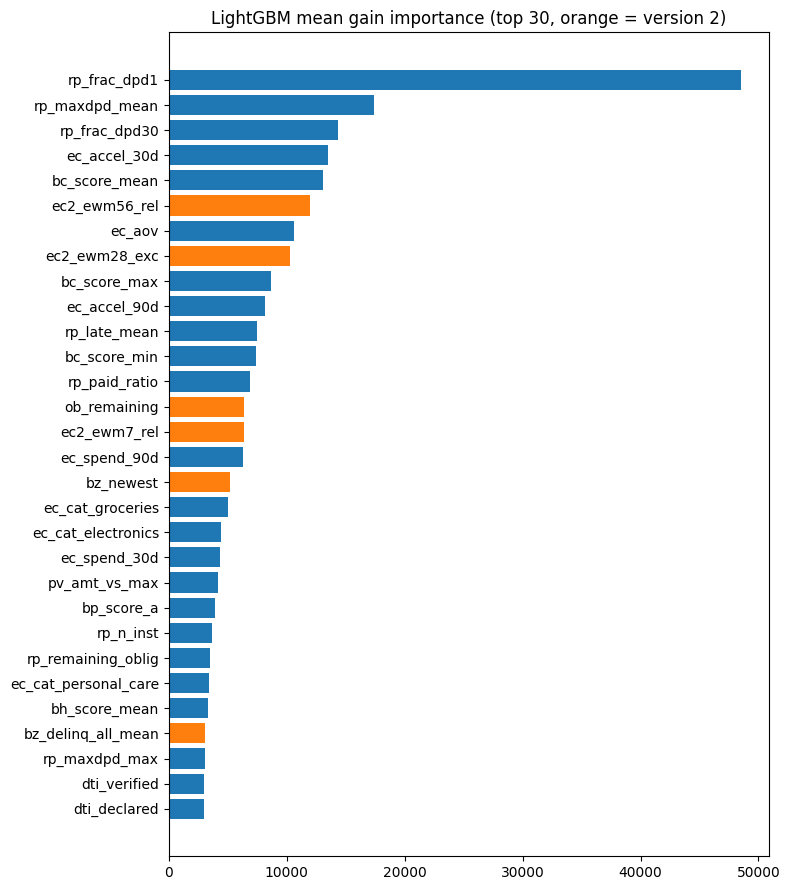

In [23]:
if LGB_MODELS:
    imp = pd.DataFrame({'feature': LGB_MODELS[0].feature_name(),
                        'gain': np.mean([m.feature_importance('gain') for m in LGB_MODELS], axis=0)})
    imp = imp.sort_values('gain', ascending=False).head(30)
    fig, ax = plt.subplots(figsize=(8, 9))
    ax.barh(imp['feature'][::-1], imp['gain'][::-1], color=['C1' if f.startswith(V2_PREFIX) else 'C0' for f in imp['feature'][::-1]])
    ax.set_title('LightGBM mean gain importance (top 30, orange = version 2)')
    plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'lgb_importance.png', dpi=90); plt.show()

## XGBoost

XGBoost runs the histogram algorithm on the GPU with native categorical support.

In [24]:
D_TE = xgb.DMatrix(X_te, enable_categorical=True)

def make_xgb_fit(params):
    def fit(tri, vai, seed):
        dtr = xgb.DMatrix(X_tr.iloc[tri], y[tri], enable_categorical=True)
        dva = xgb.DMatrix(X_tr.iloc[vai], y[vai], enable_categorical=True)
        m = xgb.train({**params, 'seed': seed}, dtr, CFG.N_ROUNDS, evals=[(dva, 'va')],
                      early_stopping_rounds=CFG.EARLY_STOP, verbose_eval=False)
        it = (0, m.best_iteration + 1)
        return m.predict(dva, iteration_range=it), m.predict(D_TE, iteration_range=it)
    return fit

if CFG.USE_XGB:
    run_gbdt('xgb', make_xgb_fit(CFG.XGB_PARAMS))
    run_gbdt('xgb_s', make_xgb_fit(CFG.XGB_SHALLOW))

  xgb seed 42: fold KS [0.5031 0.516  0.5251 0.5096 0.4916]  (51s)
  xgb seed 7: fold KS [0.5163 0.5038 0.5066 0.5166 0.4974]  (102s)
  xgb seed 2026: fold KS [0.5055 0.5057 0.524  0.5028 0.5107]  (154s)
[xgb] OOF KS=0.5092  AUC=0.8364  fold KS=0.5090+-0.0090  sim |pub-priv| p50=0.0093 p95=0.0252
  xgb_s seed 42: fold KS [0.5063 0.5133 0.5235 0.5094 0.4935]  (53s)
  xgb_s seed 7: fold KS [0.5111 0.5062 0.5077 0.5192 0.4987]  (103s)
  xgb_s seed 2026: fold KS [0.511  0.5067 0.5233 0.5    0.5138]  (154s)
[xgb_s] OOF KS=0.5104  AUC=0.8365  fold KS=0.5096+-0.0082  sim |pub-priv| p50=0.0092 p95=0.0263


## CatBoost

CatBoost trains on the GPU with ordered target statistics for the four categorical columns, which are passed as strings. Its symmetric trees already have an additive flavour, so the shallow variant uses depth 4.

In [25]:
XC_TR, XC_TE = X_tr.copy(), X_te.copy()
for c in CAT_COLS:
    XC_TR[c] = XC_TR[c].astype(str)
    XC_TE[c] = XC_TE[c].astype(str)

def make_cat_fit(params):
    def fit(tri, vai, seed):
        m = CatBoostClassifier(**params, random_seed=seed)
        m.fit(Pool(XC_TR.iloc[tri], y[tri], cat_features=CAT_COLS),
              eval_set=Pool(XC_TR.iloc[vai], y[vai], cat_features=CAT_COLS))
        return m.predict_proba(XC_TR.iloc[vai])[:, 1], m.predict_proba(XC_TE)[:, 1]
    return fit

if CFG.USE_CAT:
    run_gbdt('cat', make_cat_fit(CFG.CAT_PARAMS))
    run_gbdt('cat_s', make_cat_fit(CFG.CAT_SHALLOW))

  cat seed 42: fold KS [0.5119 0.5173 0.5249 0.5102 0.4939]  (189s)
  cat seed 7: fold KS [0.5094 0.5056 0.5054 0.5203 0.4935]  (363s)
  cat seed 2026: fold KS [0.5067 0.5033 0.5158 0.4968 0.5132]  (538s)
[cat] OOF KS=0.5070  AUC=0.8352  fold KS=0.5086+-0.0090  sim |pub-priv| p50=0.0086 p95=0.0267
  cat_s seed 42: fold KS [0.5082 0.5109 0.5269 0.516  0.4913]  (191s)
  cat_s seed 7: fold KS [0.5073 0.5112 0.5093 0.5146 0.4982]  (347s)
  cat_s seed 2026: fold KS [0.5094 0.4996 0.5195 0.4963 0.5153]  (527s)
[cat_s] OOF KS=0.5071  AUC=0.8351  fold KS=0.5089+-0.0091  sim |pub-priv| p50=0.0087 p95=0.0271


#### Insights

> Compare each model's OOF KS against version 1 (deep LightGBM 0.5057, XGBoost 0.5059, CatBoost 0.5041, public leaderboard 0.531) and against the model-free baseline of about 0.41. The ablation isolates what the new features add, and the deep-versus-shallow pairs show whether the additive bias helps. A difference smaller than the fold standard deviation (about 0.01) should not drive a decision on its own. The blend below weighs every variant by its out-of-fold contribution.

---

# Foundation and Neural Models <a name="7"></a>

---

TabPFN-3.5 is a pretrained transformer that predicts in-context: the training rows are the prompt, and no gradient step is taken on this data. TabM is a neural network trained from scratch, an efficient ensemble of 32 MLPs that share most weights. Both bring an inductive bias different from tree ensembles, which is what a blend needs.

In version 2 both foundation models trailed the trees by about 0.025 KS in every segment, including thin-file customers, and received zero blend weight. Their residual test against the tree blend was at noise level. The setup was the bottleneck: half of each training fold was dropped to fit a 30,000-row context, and only 64 features were kept. TabPFN-3.5 supports up to one million rows, so version 3 removes both limits.

## Feature Subset and Context

Inside each fold, numeric features are ranked by univariate KS on the fold's training part only, which avoids selection leakage. Near-duplicates (Spearman correlation above 0.95) are dropped greedily, and the top `FM_N_FEATURES` are kept with the categorical codes. Each model gets a time budget: if the first fold projects past it, the model is skipped and the notebook moves on. On a CUDA out-of-memory error the context halves automatically.

In [26]:
def select_fm_features(idx):
    sub, yy = X_tr.iloc[idx], y[idx]
    ranked = sorted(NUM_COLS, key=lambda c: -ks_nan(yy, sub[c].to_numpy(dtype=float)))[:2 * CFG.FM_N_FEATURES]
    corr = sub[ranked].rank().corr().abs()
    keep = []
    for c in ranked:
        if all(corr.loc[c, k] < 0.95 for k in keep):
            keep.append(c)
        if len(keep) == CFG.FM_N_FEATURES:
            break
    return keep + CAT_COLS

def fm_matrix(df, cols):
    out = df[cols].copy()
    for c in CAT_COLS:
        out[c] = out[c].cat.codes
    return out.to_numpy(dtype=np.float32)

def stratified_subsample(idx, n, seed):
    if len(idx) <= n:
        return idx
    rng = np.random.default_rng(seed)
    pos, neg = idx[y[idx] == 1], idx[y[idx] == 0]
    k = int(round(n * len(pos) / len(idx)))
    return np.r_[rng.choice(pos, k, replace=False), rng.choice(neg, n - k, replace=False)]

def predict_chunks(m, X):
    if getattr(m, 'whole_query', False):
        return m.predict_proba(X)[:, 1]
    return np.concatenate([m.predict_proba(X[i:i + CFG.FM_CHUNK])[:, 1] for i in range(0, len(X), CFG.FM_CHUNK)])

def run_fm(name, make_model, max_context, budget_min):
    oof, test_pred, fold_ks = np.zeros(len(y)), np.zeros(len(X_te)), []
    ctx, t0 = max_context, time.time()
    for k, (tri, vai) in enumerate(folds(CFG.SEED)):
        cols = select_fm_features(tri)
        cat_idx = [cols.index(c) for c in CAT_COLS]
        Xv, Xt = fm_matrix(X_tr.iloc[vai], cols), fm_matrix(X_te, cols)
        while True:
            ci, m = stratified_subsample(tri, ctx, CFG.SEED + k), None
            try:
                m = make_model(cat_idx)
                m.fit(fm_matrix(X_tr.iloc[ci], cols), y[ci])
                pq = predict_chunks(m, np.vstack([Xv, Xt]))
                pv, pt = pq[:len(Xv)], pq[len(Xv):]
                break
            except (torch.cuda.OutOfMemoryError, RuntimeError) as e:
                if 'out of memory' not in str(e).lower():
                    raise
                del m; gc.collect(); torch.cuda.empty_cache()
                ctx //= 2
                print(f'  OOM -> context reduced to {ctx}')
                if ctx < 2000:
                    raise
        oof[vai], test_pred = pv, test_pred + pt / CFG.N_FOLDS
        fold_ks.append(ks_score(y[vai], pv))
        elapsed = time.time() - t0
        print(f'  {name} fold {k}: KS={fold_ks[-1]:.4f} ctx={len(ci)} feats={len(cols)} ({elapsed:.0f}s)')
        del m; gc.collect(); torch.cuda.empty_cache()
        if k == 0 and elapsed * CFG.N_FOLDS > budget_min * 60:
            print(f'  {name} skipped: projected {elapsed * CFG.N_FOLDS / 60:.0f} min > budget {budget_min} min')
            return
    report(name, oof, fold_ks, test_pred)

## TabPFN-3.5

TabPFN-3.5 now receives the full training fold (about 56,000 rows) and 100 features. Version 2 was also slow for a second reason: without a cache, every 5,000-row prediction chunk re-encoded the whole context, which meant nine context passes per fold. `fit_mode='fit_with_cache'` encodes the context once into a KV cache and reuses it for all validation and test rows. If that runs out of memory or fails, the run falls back to `fit_preprocessors` with the ensemble members spread over both GPUs.

In [27]:
def make_tabpfn(fit_mode, device):
    def make(cat_idx):
        m = TabPFNClassifier(n_estimators=CFG.FM_N_EST, device=device, fit_mode=fit_mode, ignore_pretraining_limits=True,
                             categorical_features_indices=cat_idx, random_state=CFG.SEED)
        m.whole_query = fit_mode == 'fit_with_cache'
        return m
    return make

if CFG.USE_TABPFN and TabPFNClassifier is not None and torch.cuda.is_available():
    attempts = [('fit_with_cache', 'cuda:0'),
                ('fit_preprocessors', ['cuda:0', 'cuda:1'] if CFG.N_GPU > 1 else 'cuda:0')]
    for fit_mode, dev in attempts:
        try:
            print(f'TabPFN-3.5: fit_mode={fit_mode} device={dev}')
            run_fm('tabpfn', make_tabpfn(fit_mode, dev), CFG.FM_MAX_CONTEXT, CFG.TABPFN_BUDGET_MIN)
            break
        except Exception as e:
            print(f'  failed: {e!r}')
            gc.collect(); torch.cuda.empty_cache()

TabPFN-3.5: fit_mode=fit_with_cache device=cuda:0


tabpfn-v3.5-20260909.safetensors: reconstructing file:   0%|          |  0.00B /  876MB            

tabpfn-v3.5-20260909.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/36.0 [00:00<?, ?B/s]

  tabpfn fold 0: KS=0.5034 ctx=56000 feats=104 (307s)
  tabpfn fold 1: KS=0.4982 ctx=56000 feats=104 (600s)
  tabpfn fold 2: KS=0.5183 ctx=56000 feats=104 (892s)
  tabpfn fold 3: KS=0.5087 ctx=56000 feats=104 (1185s)
  tabpfn fold 4: KS=0.4847 ctx=56000 feats=104 (1477s)
[tabpfn] OOF KS=0.4995  AUC=0.8308  fold KS=0.5027+-0.0112  sim |pub-priv| p50=0.0099 p95=0.0281


## TabM

A neural network needs inputs on a common scale, without missing values. The offline check (`eda/32_nn_prep_verify.py`) confirmed the preparation below on the real data:

- Every numeric column is mapped through its mid-rank empirical CDF to a standard normal. The map is fitted on training rows only and uses no labels. It preserves the order of values, so the univariate KS is identical to the raw column (maximum difference 0.0).
- A value shared by many rows lands in the middle of its tie block. For example, the 60% of customers with no order in the last 7 days map to -0.52 rather than to an extreme.
- Missing values become 0, the median of the normal scale. One indicator per distinct missingness pattern (29 groups) tells the network which tables are absent. The largest group is the 61 columns that thin-file customers miss together.
- Heavy tails such as income become close to normal, and train-to-test PSI stays at 0.001.

TabM then uses piecewise-linear embeddings with 48 quantile bins per feature and is trained with the mean binary cross-entropy of its 32 members. Each member must be trained on its own loss. Early stopping uses validation AUC, and the members' probabilities are averaged for prediction. It runs over the same 3 seeds x 5 folds as the trees. Two time guards act inside the run rather than after it: each fold stops training after `TABM_FOLD_MAX_MIN` minutes and keeps its best epoch so far, and the model is dropped after its first fold if the projected total exceeds `TABM_BUDGET_MIN`.

In [28]:
def nn_prep(train: np.ndarray, test: np.ndarray):
    train = np.where(np.isfinite(train), train, np.nan)
    test = np.where(np.isfinite(test), test, np.nan)
    ref = [np.sort(train[~np.isnan(train[:, j]), j]) for j in range(train.shape[1])]
    keep = [j for j, s in enumerate(ref) if len(s) and s[0] < s[-1]]

    def transform(a):
        out = np.zeros((a.shape[0], len(keep)), np.float32)
        for i, j in enumerate(keep):
            s, x = ref[j], a[:, j]
            m = ~np.isnan(x)
            u = (np.searchsorted(s, x[m], side="left") + np.searchsorted(s, x[m], side="right")) / (2 * len(s))
            out[m, i] = np.clip(ndtri(np.clip(u, 0.5 / len(s), 1 - 0.5 / len(s))), -5, 5)
        return out

    miss_tr, miss_te = np.isnan(train[:, keep]), np.isnan(test[:, keep])
    seen, ind_cols = set(), []
    for i in range(miss_tr.shape[1]):
        key = np.packbits(miss_tr[:, i]).tobytes()
        if miss_tr[:, i].any() and key not in seen:
            seen.add(key)
            ind_cols.append(i)
    Xtr = np.hstack([transform(train), miss_tr[:, ind_cols].astype(np.float32)])
    Xte = np.hstack([transform(test), miss_te[:, ind_cols].astype(np.float32)])
    return Xtr, Xte, {"kept": keep, "indicator_of": ind_cols}

In [29]:
if CFG.USE_TABM and tabm is not None and torch.cuda.is_available():
    XN_TR, XN_TE, nn_info = nn_prep(X_tr[NUM_COLS].to_numpy(dtype=float), X_te[NUM_COLS].to_numpy(dtype=float))
    CARDS = [len(X_tr[c].cat.categories) for c in CAT_COLS]
    XCAT_TR = np.column_stack([X_tr[c].cat.codes.to_numpy() for c in CAT_COLS]).astype(np.int64)
    XCAT_TE = np.column_stack([X_te[c].cat.codes.to_numpy() for c in CAT_COLS]).astype(np.int64)
    print(f'TabM input: {XN_TR.shape[1]} numeric columns ({len(nn_info["kept"])} features + {len(nn_info["indicator_of"])} missing groups), '
          f'{len(CARDS)} categorical; finite={np.isfinite(XN_TR).all() and np.isfinite(XN_TE).all()}')

TabM input: 239 numeric columns (210 features + 29 missing groups), 4 categorical; finite=True


In [30]:
DEV = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

def tabm_predict(model, xn, xc):
    model.eval()
    with torch.no_grad():
        return torch.cat([torch.sigmoid(model(xn[i:i + 8192], xc[i:i + 8192]).squeeze(-1).float()).mean(1)
                          for i in range(0, len(xn), 8192)]).cpu().numpy()

def tabm_fit(tri, vai, seed):
    torch.manual_seed(seed)
    xn, xc = torch.as_tensor(XN_TR, device=DEV), torch.as_tensor(XCAT_TR, device=DEV)
    yt = torch.as_tensor(y, dtype=torch.float32, device=DEV)
    tri_t, vai_t = torch.as_tensor(tri, device=DEV), torch.as_tensor(vai, device=DEV)
    emb = rtdl_num_embeddings.PiecewiseLinearEmbeddings(
        rtdl_num_embeddings.compute_bins(xn[tri_t], n_bins=CFG.TABM_BINS), d_embedding=16, activation=False, version='B')
    model = tabm.TabM.make(n_num_features=xn.shape[1], cat_cardinalities=CARDS, d_out=1, num_embeddings=emb).to(DEV)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG.TABM_LR, weight_decay=CFG.TABM_WD)
    best, best_state, wait, t_fold = -1.0, None, 0, time.time()
    for epoch in range(CFG.TABM_EPOCHS):
        model.train()
        for idx in tri_t[torch.randperm(len(tri_t), device=DEV)].split(CFG.TABM_BATCH):
            out = model(xn[idx], xc[idx]).squeeze(-1)
            loss = torch.nn.functional.binary_cross_entropy_with_logits(out, yt[idx].unsqueeze(1).expand_as(out))
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        auc = roc_auc_score(y[vai], tabm_predict(model, xn[vai_t], xc[vai_t]))
        if auc > best:
            best, best_state, wait = auc, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
        if wait >= CFG.TABM_PATIENCE or time.time() - t_fold > CFG.TABM_FOLD_MAX_MIN * 60:
            break
    model.load_state_dict(best_state)
    pv = tabm_predict(model, xn[vai_t], xc[vai_t])
    pt = tabm_predict(model, torch.as_tensor(XN_TE, device=DEV), torch.as_tensor(XCAT_TE, device=DEV))
    del model, opt, xn, xc; gc.collect(); torch.cuda.empty_cache()
    return pv, pt

if CFG.USE_TABM and tabm is not None and torch.cuda.is_available():
    try:
        run_gbdt('tabm', tabm_fit, budget_min=CFG.TABM_BUDGET_MIN)
    except Exception as e:
        print('TabM skipped:', repr(e))

  tabm seed 42: fold KS [0.518  0.5205 0.5287 0.5146 0.4983]  (566s)
  tabm seed 7: fold KS [0.515  0.5166 0.5135 0.5259 0.5014]  (1156s)
  tabm seed 2026: fold KS [0.5137 0.5113 0.5182 0.5011 0.5202]  (1744s)
[tabm] OOF KS=0.5126  AUC=0.8383  fold KS=0.5145+-0.0084  sim |pub-priv| p50=0.0089 p95=0.0257


#### Insights

> Compare each model with version 2: TabPFN 0.4864 and Causilo 0.4848 OOF KS with a capped context, against 0.5104 for the equal-weight tree blend. A first version 3 run already showed that lifting the context cap moves TabPFN-3.5 to 0.4995 OOF KS in 25 minutes, which confirms the setup diagnosis but leaves it below the trees. A non-tree model does not need to beat the trees to help. What matters is whether it ranks some customers differently and correctly, which the blend below measures on held-out halves.

---

# Ensemble and KS Stability <a name="8"></a>

---

KS depends only on ranks, so each model's predictions are converted to normalised ranks before blending. Weights come from greedy ensemble selection (Caruana et al.): starting from an empty blend, the model whose addition gives the highest OOF KS is added, with replacement, `ENS_ITERS` times, and the weights are the selection counts. In-sample selection is optimistic, so it is cross-checked: weights fitted on one half of the OOF rows are scored on the other half. The reference is the equal-weight blend of the six tree models, which needs no fitting. Greedy weights are used only if they beat that reference on held-out halves. Each non-tree model is also scored at a fixed 20% share, which shows its contribution without any fitting.

In [31]:
names = list(RESULTS)
R_OOF = np.column_stack([rankdata(RESULTS[n]['oof']) / len(y) for n in names])
R_TE = np.column_stack([rankdata(RESULTS[n]['test']) / len(X_te) for n in names])
print(pd.DataFrame(R_OOF, columns=names).corr().round(3))

def best_weights(rows):
    counts, cur = np.zeros(len(names)), np.zeros(len(rows))
    for it in range(CFG.ENS_ITERS):
        cand = [(cur * it + R_OOF[rows, j]) / (it + 1) for j in range(len(names))]
        j = int(np.argmax([ks_score(y[rows], c) for c in cand]))
        counts[j] += 1
        cur = cand[j]
    return counts / counts.sum()

TREES = ('lgb', 'lgb_s', 'xgb', 'xgb_s', 'cat', 'cat_s')
w_tree = np.array([1.0 if n in TREES else 0.0 for n in names]); w_tree /= w_tree.sum()
w_best = best_weights(np.arange(len(y)))
half = np.random.default_rng(0).permutation(len(y))
a, b = half[: len(y) // 2], half[len(y) // 2:]
w_a, w_b = best_weights(a), best_weights(b)
held_greedy = (ks_score(y[b], R_OOF[b] @ w_a) + ks_score(y[a], R_OOF[a] @ w_b)) / 2
held_tree = (ks_score(y[b], R_OOF[b] @ w_tree) + ks_score(y[a], R_OOF[a] @ w_tree)) / 2
print(f'held-out halves: greedy {held_greedy:.4f} vs equal-weight trees {held_tree:.4f}')
print('greedy weights fitted per half:', dict(zip(names, np.round(w_a, 2))), dict(zip(names, np.round(w_b, 2))))
W = w_best if held_greedy > held_tree else w_tree
print('chosen weights:', dict(zip(names, np.round(W, 2))), '(greedy)' if W is w_best else '(equal-weight trees)')
non_tree = [n for n in names if n not in TREES]
for n in non_tree:
    j = names.index(n)
    w_add = 0.8 * w_tree + 0.2 * np.eye(len(names))[j]
    print(f'  adding {n} at 20% to the tree blend: held-out halves '
          f'{(ks_score(y[b], R_OOF[b] @ w_add) + ks_score(y[a], R_OOF[a] @ w_add)) / 2:.4f} (trees alone {held_tree:.4f})')

blend_oof, blend_te = R_OOF @ W, R_TE @ W
for n in names:
    print(f'  {n:<8} OOF KS {ks_score(y, RESULTS[n]["oof"]):.4f}')
print(f'  BLEND    OOF KS {ks_score(y, blend_oof):.4f}   (version 2 blend: 0.5134 in-sample greedy, 0.5104 equal-weight trees)')

          lgb  lgb_s    xgb  xgb_s    cat  cat_s  tabpfn   tabm
lgb     1.000  0.995  0.997  0.995  0.985  0.984   0.965  0.983
lgb_s   0.995  1.000  0.996  0.999  0.988  0.988   0.966  0.986
xgb     0.997  0.996  1.000  0.996  0.986  0.985   0.965  0.984
xgb_s   0.995  0.999  0.996  1.000  0.988  0.988   0.965  0.986
cat     0.985  0.988  0.986  0.988  1.000  0.998   0.967  0.982
cat_s   0.984  0.988  0.985  0.988  0.998  1.000   0.967  0.981
tabpfn  0.965  0.966  0.965  0.965  0.967  0.967   1.000  0.961
tabm    0.983  0.986  0.984  0.986  0.982  0.981   0.961  1.000
held-out halves: greedy 0.5138 vs equal-weight trees 0.5109
greedy weights fitted per half: {'lgb': np.float64(0.03), 'lgb_s': np.float64(0.2), 'xgb': np.float64(0.27), 'xgb_s': np.float64(0.0), 'cat': np.float64(0.0), 'cat_s': np.float64(0.0), 'tabpfn': np.float64(0.0), 'tabm': np.float64(0.5)} {'lgb': np.float64(0.3), 'lgb_s': np.float64(0.07), 'xgb': np.float64(0.0), 'xgb_s': np.float64(0.13), 'cat': np.float64(0.13),

## KS Stability Checks

The blend is checked along four axes: per-fold KS, the simulated public/private gap at 30% and 50% public shares, KS inside the thin-file and history segments, and KS per decision month. A stable model shows small spreads on all four.

blend fold KS: [0.5149 0.5207 0.5278 0.5148 0.4972]  mean=0.5151 sd=0.0101
public share 30%: simulated |KS_pub - KS_priv| median=0.0103 p95=0.0291
public share 50%: simulated |KS_pub - KS_priv| median=0.0094 p95=0.0255
thin-file     n= 21000 bad=0.117 KS=0.4768
with history  n= 49000 bad=0.144 KS=0.5279
KS by decision month: [0.527 0.512 0.5   0.549 0.531 0.52  0.543 0.525 0.487 0.541 0.5   0.499] sd=0.0191


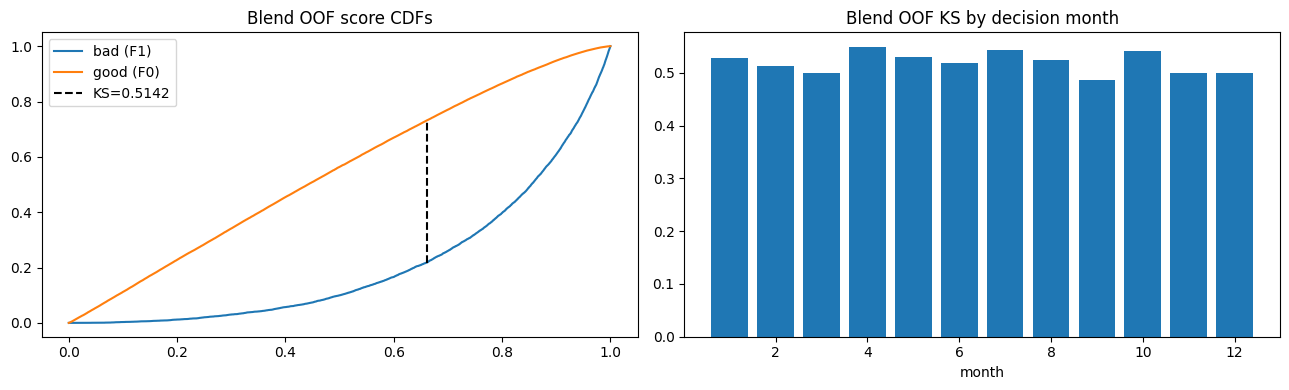

In [32]:
fk = [ks_score(y[v], blend_oof[v]) for _, v in folds(CFG.SEED)]
print(f'blend fold KS: {np.round(fk, 4)}  mean={np.mean(fk):.4f} sd={np.std(fk):.4f}')
for share in (0.3, 0.5):
    med, p95 = gap_simulation(blend_oof, public_share=share)
    print(f'public share {share:.0%}: simulated |KS_pub - KS_priv| median={med:.4f} p95={p95:.4f}')
hist = tr_f['has_history'].to_numpy()
for g, lab in [(0, 'thin-file'), (1, 'with history')]:
    msk = hist == g
    print(f'{lab:<13} n={msk.sum():>6} bad={y[msk].mean():.3f} KS={ks_score(y[msk], blend_oof[msk]):.4f}')
month = tr_f['decision_datetime'].dt.month().to_numpy()
mk = [ks_score(y[month == mth], blend_oof[month == mth]) for mth in range(1, 13)]
print('KS by decision month:', np.round(mk, 3), f'sd={np.std(mk):.4f}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
s = np.sort(blend_oof)
f1 = np.searchsorted(np.sort(blend_oof[y == 1]), s, side='right') / (y == 1).sum()
f0 = np.searchsorted(np.sort(blend_oof[y == 0]), s, side='right') / (y == 0).sum()
i = np.argmax(np.abs(f1 - f0))
ax[0].plot(s, f1, label='bad (F1)'); ax[0].plot(s, f0, label='good (F0)')
ax[0].vlines(s[i], f1[i], f0[i], color='k', ls='--', label=f'KS={abs(f1[i] - f0[i]):.4f}')
ax[0].set_title('Blend OOF score CDFs'); ax[0].legend()
ax[1].bar(range(1, 13), mk); ax[1].set_title('Blend OOF KS by decision month'); ax[1].set_xlabel('month')
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'ks_stability.png', dpi=90); plt.show()

#### Insights

> A simulated public/private gap of about 0.01 is the noise floor for a 30,000-row test set with about 4,000 bad loans. A leaderboard gap of that size is expected and does not indicate overfitting. A gap well above the simulated 95th percentile would point to a distribution problem rather than chance.

> Similar KS in the thin-file and history segments, and a flat month profile, show that the blend does not rely on a single sub-population or period. Those are the conditions for the public and private scores to stay close.

---

# Submission <a name="9"></a>

---

The blended test ranks are min-max scaled into [0, 1], which leaves the KS unchanged. The file is validated against every rule in the competition description before it is written.

In [33]:
def to_unit(p):
    return (p - p.min()) / (p.max() - p.min())

def write_submission(pred, path):
    sub = pl.DataFrame({'application_id': test_ids, 'default_probability': to_unit(pred)})
    assert sub.height == sample_sub.height == T['test_applications'].height
    assert sub['application_id'].n_unique() == sub.height
    assert set(sub['application_id']) == set(sample_sub['application_id'])
    assert sub['default_probability'].is_finite().all()
    assert sub['default_probability'].is_between(0, 1).all()
    sub.write_csv(path)
    print('wrote', path, sub.shape)
    return sub

submission = write_submission(blend_te, CFG.OUTPUT_DIR / 'submission.csv')
gbdt = [i for i, n in enumerate(names) if n in TREES]
if gbdt:
    write_submission(R_TE[:, gbdt].mean(1), CFG.OUTPUT_DIR / 'submission_gbdt_only.csv')
print(submission.head())

wrote /kaggle/working/submission.csv (30000, 2)
wrote /kaggle/working/submission_gbdt_only.csv (30000, 2)
shape: (5, 2)
┌────────────────────┬─────────────────────┐
│ application_id     ┆ default_probability │
│ ---                ┆ ---                 │
│ str                ┆ f64                 │
╞════════════════════╪═════════════════════╡
│ A_779e4e5a0ca90902 ┆ 0.201964            │
│ A_289cbaf13ec58feb ┆ 0.530407            │
│ A_172169d79a3f4a35 ┆ 0.131869            │
│ A_51ff46a3e1427786 ┆ 0.965968            │
│ A_bd7e505dcbebaf89 ┆ 0.801199            │
└────────────────────┴─────────────────────┘


#### Insights

> `submission.csv` is the final blend. `submission_gbdt_only.csv` is a fallback built only from the tree models, and it is useful as a second leaderboard data point. If the two differ on the public board by less than the simulated noise floor, choose the final submission by OOF KS.